# Evoluzione degli anime negli anni

C'è un momento in cui un prodotto culturale smette di essere intrattenimento e diventa industria. Per gli anime, quel momento è già passato da un pezzo, e molti non se ne sono ancora accorti.
Quello che è nato come animazione per bambini nei sabati mattina giapponesi è diventato oggi uno dei fenomeni di export culturale più potenti al mondo. Merchandise, licensing, streaming, eventi, turismo: l'anime non vende solo storie, vende universi. E gli universi, si sa, non hanno confini geografici né limiti di scala.
I numeri dell'industria parlano da soli. Ma i dati che seguono raccontano qualcosa di più sottile: non solo quanto è cresciuto questo fenomeno, ma come, quali demografiche hanno guidato la corsa, dove si concentra il pubblico globale, cosa scelgono davvero i fan.

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from solution.utils import utils


In [2]:
# load dataset
df_details = pd.read_csv("../../dataset/cleaned/details_cleaned.csv")
df_favs = pd.read_csv("../../dataset/cleaned/favs_cleaned.csv")
df_recommendations = pd.read_csv("../../dataset/cleaned/recommendations_cleaned.csv")
df_stats = pd.read_csv("../../dataset/cleaned/stats_cleaned.csv")
df_ratings = pd.read_csv("../../dataset/cleaned/ratings_cleaned.csv")
df_profiles = pd.read_csv("../../dataset/cleaned/profiles_cleaned.csv")
df_person_anime_works = pd.read_csv("../../dataset/cleaned/person_anime_works_cleaned.csv")
df_person_details = pd.read_csv("../../dataset/cleaned/person_details_cleaned.csv")
df_person_alternate_names = pd.read_csv("../../dataset/cleaned/person_alternate_names_cleaned.csv")
df_characters_anime_works = pd.read_csv("../../dataset/cleaned/character_anime_works_cleaned.csv")
df_person_voice_works = pd.read_csv("../../dataset/cleaned/person_voice_works_cleaned.csv")
df_characters = pd.read_csv("../../dataset/cleaned/characters_cleaned.csv")
df_character_nicknames = pd.read_csv("../../dataset/cleaned/character_nicknames_cleaned.csv")

In [3]:
df_details['start_date'] = pd.to_datetime(df_details['start_date'], errors='coerce')
df_details['year'] = df_details['start_date'].dt.year.astype("Int64")
df_details['scored_by'] = pd.to_numeric(df_details['scored_by'], errors='coerce')
df_person_details["birthday"] = pd.to_datetime(df_person_details["birthday"], errors="coerce")
df_person_details["birth_year"] = df_person_details["birthday"].dt.year.astype("Int64")
df_person_details["favorites"] = pd.to_numeric(df_person_details["favorites"], errors="coerce")
df_details["favorites"] = pd.to_numeric(df_details["favorites"], errors="coerce")
df_details["score"]= pd.to_numeric(df_details["score"],errors="coerce")

## 1. LA CRESCITA STORICA DELLA PRODUZIONE ANIME

### Come si è evoluta la produzione di anime nel tempo?

In [4]:
details = df_details.copy()

# rimuove le righe senza data di inizio
details = details.dropna(subset=['start_date'])
# conta quanti anime ci sono per ogni anno
counts = (details['year'].value_counts().sort_index().reset_index())
# rinomina le colonne
counts.columns = ['year', 'anime_count']
# creazione grafico con Plotly
fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

**La parabola della produzione: dal silenzio all'esplosione**

Per gran parte del Novecento, l'industria degli anime ha proceduto con un passo lento e constante. è stato un cammino silenzioso, fatto di sperimentazione e artigianalità, dove la produzione cresceva senza scosse evidenti. Ma è con l'arrivo degli anni '80 che qualcosa inizia a cambiare: il battito accelera, segnalando un interesse che travalica i confini nazionali.

**Il Nuovo Millennio e il picco storico**

Tuttavia, è dopo il 2000 che assistiamo a una vera e propria metamorfosi. La curva della produzione cambia ritmo in modo prepotente, spinta dalla digitalizzazione e da una domanda globale sempre più vorace. Questo crescendo culmina nel **2017**: l'anno d'oro, il vertice masssimo di un'espansione durata due decenni, in cui l'industria ha toccato il suo apice storico.

**Oltre la vetta: un nuovo equilibro**

Negli anni più recenti, i dati mostrano una lieva flessione. Non è però un segnale di crisi, ma il riflesso di un mercato che, dopo aver toccato vette incredibile nel 2017, cerca ora un nuovo equilibro. La tendenza generale rimane solida: il gigante è sveglio e continua a correre, consolidando la sua eredigtà come ecosistema culturale globale.
> **Nota sui dati:** su un totale di 28.955 titoli, 851 anime privi di data di inizio (2,9 % del dataset) sono stati esclusi da questo grafico. Il dataset contiene 157 titoli con anno 2026–2027 (annunciati ma non ancora usciti). Il grafico è volutamente limitato al 2024 per mostrare solo produzioni concluse.

### L'albero genealogico degli anime: distribuzione dei generi

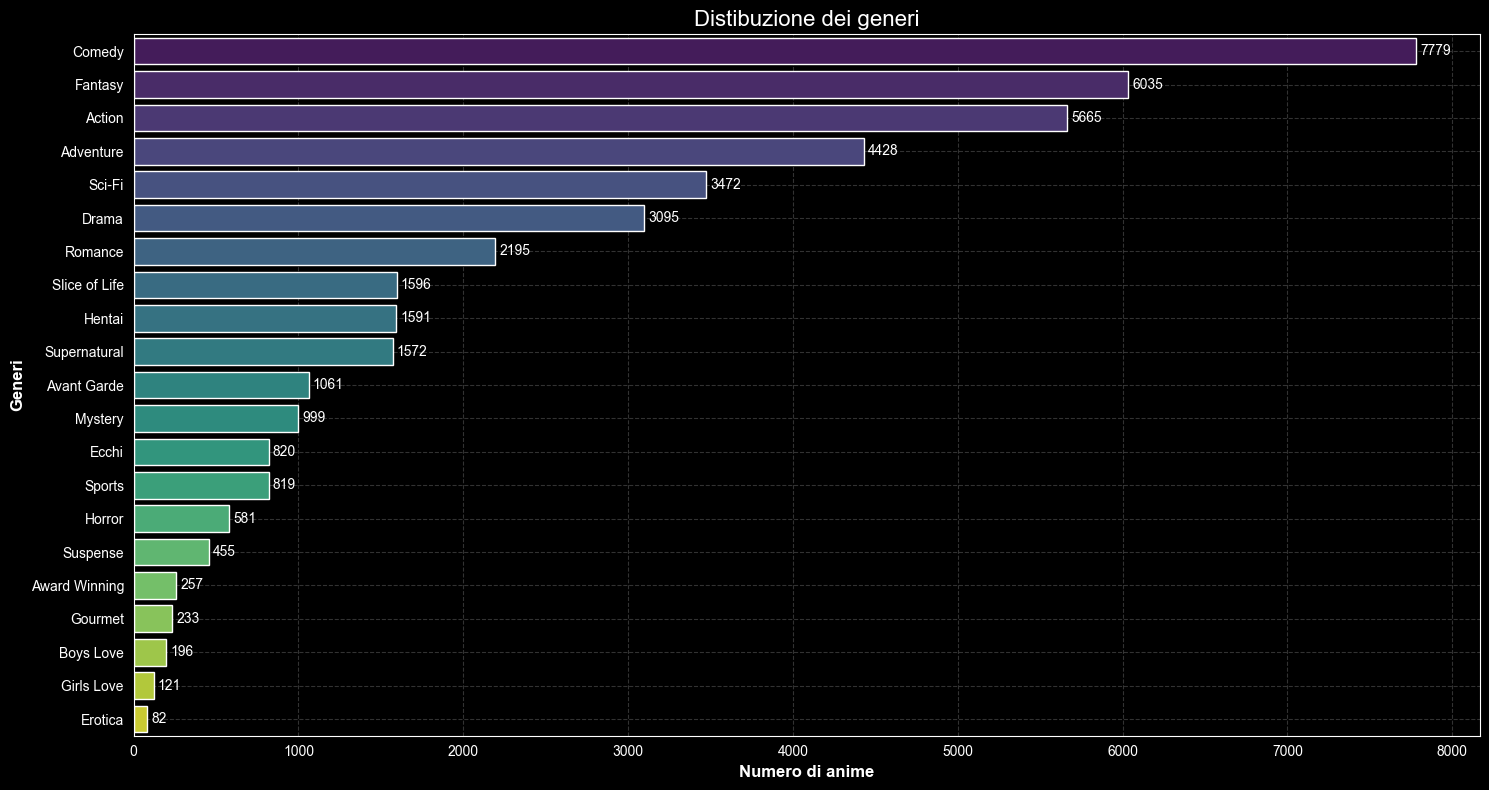

In [5]:
df_genres = df_details['genres'].copy()

# converte ogni valore da stringa in una lista
df_genres = df_genres.apply(utils.parse_genres)
# esplode le liste: ogni genere diventa una riga separata
df_genres = df_genres.explode().dropna()
# conta quante volte appare ogni genere
genre_count = df_genres.value_counts().reset_index()
# rinomia colonne
genre_count.columns = ['genre', 'count']

# crea grafico
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
# per ogni barra mostra il numero esatto di anime
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Distibuzione dei generi', fontsize=16)
plt.xlabel('Numero di anime', fontsize=12, fontweight='bold')
plt.ylabel('Generi', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()


**I giganti del settore: i pilastri del mercato**
Se osserviamo la foresta dei contenuti prodotti, i giganti che dominano la scena sono indubbiamente la **Commedia**, l'**Azione** e il **Fantasy**. Questi generi costituiscono le fondamenta dell'intera industria: la loro popolarità universale li rende i prodotti più "sicuri" e richiesti, capaci di attrarre un pubblico vastissimo che spazia dai giovanissimi ai fan storici.

**L'equilibrio tra evasione e introspezione**

Accanto ai leader indiscussi, notiamo una presenza solida di generi come **Adventure** e **Sci-Fi**, che alimentano l'immaginario fantastico tipico del medium. Tuttavia, l'analisi rivela che non c'è solo spettacolo: il successo di titoli **Drama** e **Slice of Life** dimostra un'industria profondamente radicata nell'esplorazione dei sentimenti umani e della vita quotidiana, capace di trasformare la normalità in narrazione epica.
> **Nota sui dati:** Il 20,7 % degli anime (5.983 titoli) non ha tag di genere nel dataset e non è incluso in questo grafico né in quello successivo. La distribuzione si basa sul restante 79,3 % del catalogo.

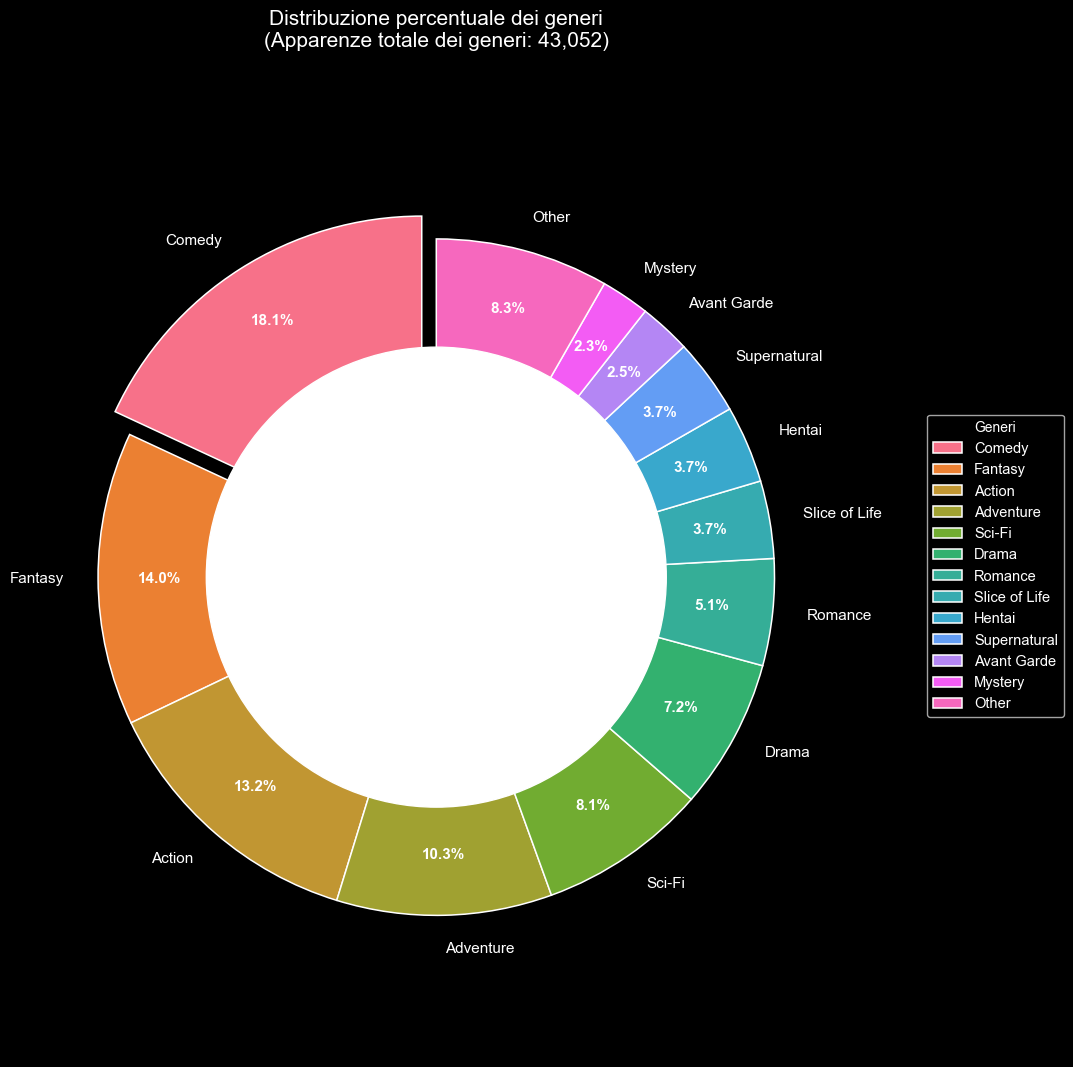

In [6]:
details = df_details.copy()

# rimuove le righe senza generi
details = details.dropna(subset=['genres'])
# usa la funzione utils per convertire la colonna generi in liste
details['genres'] = details['genres'].apply(utils.parse_genres)
# explode: una riga per ogni genere
genres_df = details.explode('genres')
# conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()

# top 12 generi + Other
top_n_pie = 12
top_genres_pie = genre_total.head(top_n_pie)

# somma il conteggio di tutti i generi rimanenti
other_count = genre_total.iloc[top_n_pie:].sum()
if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie

plt.figure(figsize=(11, 11))
colors = sns.color_palette("husl", len(pie_data))
# explode solo sulla fetta più grande
explode = [0.08 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]
wedges, texts, autotexts = plt.pie(pie_data.values,labels=pie_data.index,autopct='%1.1f%%',startangle=90,colors=colors,explode=explode,pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},textprops={'fontsize': 11})
# stile percentuali
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
plt.title(f"Distribuzione percentuale dei generi\n(Apparenze totale dei generi: {genre_total.sum():,})",fontsize=15, pad=20)
# effetto donut
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# legenda
plt.legend(pie_data.index, title="Generi", loc="center left",bbox_to_anchor=(1.15, 0.5), fontsize=10.5)
plt.axis('equal')
plt.tight_layout()
plt.show()

**L'anima del mosaico: la forza delle nicchie**

Il grafico a ciambella ci offre una prospettiva diversa e fondamentale: quella della "biodiversità" del settore. Sebbene i generi dominanti occupino le fette più grandi, la vasta area definita dalle categorie minori rivela la vera magia degli anime. Non è un mercato a senso unico, ma un mosaico composto da centinaia di sfumature diverse che convivono armoniosamente.

**Visione d'insieme: un ecosistema multiforme**

In sintesi, l'equilibrio tra i generi **mainstream** (che garantiscono la stabilità economica) e le innumerevoli **nicchie** (che preservano la vivacità artistica) è il vero segreto del successo globale. Questa distribuzione ci restituisce l'immagine di un ecosistema maturo, dove ogni spettatore, indipendentemente da quanto siano particolari i suoi gusti, potrà sempre trovare una storia originale cucita su misura per lui.

### Come sono cambiati i generi anime nel tempo?

In [7]:
df_gen_evol = df_details.copy()

# rimuove righe senza anno
df_gen_evol = df_gen_evol.dropna(subset=['year'])
# filtra solo gli anime storicamente rilevanti
df_gen_evol = df_gen_evol[(df_gen_evol['year'] >= 1917) & (df_gen_evol['year'] <= 2024)]
# rimuove righe senza generi
df_gen_evol = df_gen_evol.dropna(subset=['genres'])
# converte la stringa dei generi in lista
df_gen_evol['genres'] = df_gen_evol['genres'].apply(utils.parse_genres)
# pulisce ogni genre: rimuove spazi e mette la prima lettera maiuscola
df_gen_evol['genres'] = df_gen_evol['genres'].apply(lambda g: [gen.strip().title() for gen in g])
# explode generi
genres_df = df_gen_evol.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))

# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible=True if genre == "Action" else "legendonly",
            line=dict(width=2.5)
        )
    )
fig.update_layout(
    title="Produzione di anime nel tempo per genere",
    xaxis_title="Anno",
    yaxis_title="Numero di anime rilasciati",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Clicca sui generi per mostrare/ nascondere"
)
fig.show()

Il grafico mostra come i principali generi anime si siano evoluti nel corso degli anni, seguendo traiettorie diverse ma con un andamento comune: una crescita lenta fino agli anni ’70, seguita da un’accelerazione evidente a partire dagli anni ’80. In questa fase, generi come _Action_, _Adventure_, _Comedy_ e _Drama_ iniziano a distinguersi, aumentando progressivamente la loro presenza.
Dopo il 2000, tutte le linee mostrano un incremento più marcato, segno di un’espansione generale dell’industria. In particolare, **Comedy** e **Action** emergono come i generi più dinamici, ma con caratteristiche diverse: la Comedy cresce in modo più rapido e raggiunge valori più elevati, mentre l’Action mantiene un andamento più regolare e costante, confermandosi come uno dei pilastri storici della produzione anime. Il 2017 rappresenta un punto particolarmente significativo: in quell’anno, diversi generi tra cui proprio Comedy e Action  toccano uno dei loro massimi, evidenziando un momento di forte intensificazione produttiva.
Negli anni successivi, alcune curve mostrano una lieve flessione, mentre altre mantengono livelli elevati, suggerendo un settore che continua a essere attivo ma con ritmi più equilibrati rispetto al picco precedente.
Nel complesso, il grafico racconta una storia di crescita condivisa, in cui ogni genere segue il proprio percorso ma contribuisce a un’espansione complessiva degli anime.

## 2. DALLA PRODUZIONE ALLA VALUTAZIONE DEGLI UTENTI

In [8]:
details = df_details.copy()

# filtro per il calcolo della media pesata
df_weighted = details[details['score'].notna() & details['scored_by'].notna() &
                      (details['scored_by'] > 0) & details['year'].notna()].copy()

# limitiamo l'analisi agli anni storicamente rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]
# media pesata, totale voti, numero anime per anno
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False).reset_index()
year_weighted = year_weighted.sort_values('year')
# media mobile centrata a 5 anni
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(
    window=5, center=True, min_periods=2).mean()

# visualizzazione
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=year_weighted['year'], y=year_weighted['weighted_mean'],
    mode='lines+markers', name='Media pesata (sui voti)',
    line=dict(color='tomato', width=1.5), marker=dict(size=4),
    hovertemplate='Media pesata: %{y:.2f}<extra></extra>'))
fig.add_trace(go.Scatter(
    x=year_weighted['year'], y=year_weighted['rolling_weighted'],
    mode='lines', name='Media mobile a 5 anni',
    line=dict(color='limegreen', width=3, dash='dash'),
    hovertemplate='Media mobile: %{y:.2f}<extra></extra>'))

fig.update_layout(
    title=dict(text="Media ponderata del punteggio degli anime per anno (1917–2024)<br>"
                    "<sup>Ponderata in base al numero di voti</sup>"),
    xaxis=dict(title='Anno di inizio',
               range=[year_weighted['year'].min(), year_weighted['year'].max()]),
    yaxis=dict(title='Punteggio (0–10)', range=[0, 10]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.
> **Nota sui dati:** I decenni precedenti al 1960 presentano spesso 1–3 anime per anno e meno di 1.000 voti totali: le medie di quei periodi sono basate su campioni molto ridotti e vanno interpretate con cautela. La media mobile a 5 anni aiuta ad attenuare questi picchi isolati.


### I generi più prodotti sono anche quelli più amati dai fan?

In [9]:
details = df_details.copy().dropna(subset=['genres'])

# converte la colonna generi da stringa in lista
details['genres'] = details['genres'].apply(utils.parse_genres)
# ogni genere diventa una riga separata
genres_df = details.explode('genres')
# preferiti di tipo anime
favs = df_favs[df_favs['fav_type'] == 'anime'].copy()
# produzione: % di ogni genere sul totale
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

# preferiti: unione e % di ogni genere
favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100
# dataframe con le due percentuali affiancate, tutti i generi
compare = pd.DataFrame({'Produzione': production_pct,
                        'Preferenze fan': favs_pct}).dropna()
compare = compare.sort_values('Produzione', ascending=False)


# formato plotly
compare_long = (compare.rename_axis('Genere').reset_index()
                .melt(id_vars='Genere', var_name='Tipo', value_name='Percentuale'))

# creazione grafico con Plotly
fig = px.bar(compare_long, x='Genere', y='Percentuale', color='Tipo',
    barmode='group',
    title="Produzione vs Preferenze dei fan per genere",
    labels={'Percentuale': 'Percentuale (%)'})
fig.update_traces(hovertemplate='%{y:.2f}%<extra></extra>')
fig.update_layout(
    xaxis=dict(tickangle=-45),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Il grafico mette a confronto la percentuale di produzione degli anime per genere con le preferenze dichiarate dai fan, evidenziando in modo immediato le aree di allineamento e quelle di discrepanza. Alcuni generi, come **Comedy** e **Fantasy**, mostrano una produzione molto elevata, ma non sempre corrispondono a un interesse dei fan altrettanto forte, suggerendo una sovraofferta rispetto alla domanda.
Al contrario, generi come Drama o Romance mostrano il divario opposto: i fan li preferiscono più di quanto vengono prodotti. In altri casi, come _Hentai_ o _Slice of Life_, la produzione risulta superiore alle preferenze, mentre generi come Supernatural mostrano un rapporto più armonico tra offerta e gradimento.
Nel complesso, il grafico racconta una dinamica interessante: l’industria tende a investire maggiormente nei generi più versatili e commerciali, mentre le preferenze dei fan risultano più distribuite e talvolta orientate verso generi meno rappresentati. Questa differenza tra produzione e domanda offre uno spunto utile per comprendere come il mercato anime si adatti o talvolta non si adatti alle aspettative del pubblico.


## 3. LE ORIGINI NARRATIVE DEGLI ANIME

### Da dove nascono gli anime

In [10]:
details = df_details.copy()

# rimuovo valori nulli e cateogie non informative
details = details[(details['source'].notna()) & (details['source'] != 'Unknown') & (details['source'] != 'Other')]
# normalizzazione testo
details['source'] = details['source'].str.strip().str.title()
# conteggio per categoria
source_counts = details['source'].value_counts().reset_index()
# rinomina colonne
source_counts.columns = ['source', 'count']

# creazione treemap
fig = px.treemap(
    source_counts,
    path=['source'],
    values='count',
    color='count',
    color_continuous_scale='Blues',
    title='Da dove nascono gli anime?',
)
fig.update_traces(
    textinfo='label+value+percent root',
    textfont_size=14,
    hovertemplate='<b>%{label}</b><br>Anime: %{value:,}<br>%{percentRoot:.1%}<extra></extra>'
)
fig.update_layout(height=520, margin=dict(t=50, l=10, r=10, b=10),
                  coloraxis_colorbar=dict(title='N. anime'))
fig.show()

Il grafico mostra la distribuzione delle principali **fonti di ispirazione** degli anime, evidenziando da quali media o opere originali nasce la produzione animata giapponese.

Il dato più evidente è la **forte predominanza delle opere Original**, che rappresentano la quota maggiore. Questo suggerisce che l’industria anime mantiene una notevole capacità creativa autonoma, producendo contenuti non direttamente derivati da altri media.

Subito dopo emergono gli adattamenti da **Manga**, che confermano il ruolo centrale di questo medium come serbatoio narrativo per l’animazione giapponese. Manga e anime risultano quindi profondamente interconnessi, sia dal punto di vista artistico che industriale.

Le altre categorie (come **Light Novel**, **Game**, **Visual Novel** e **Web Manga**) hanno una presenza più contenuta ma significativa, indicando una crescente tendenza alla contaminazione tra media diversi. Questo fenomeno riflette l’evoluzione del consumo culturale, sempre più crossmediale.

Nel complesso, il grafico racconta un’industria che combina **creatività originale** e **adattamento strategico**, bilanciando innovazione e sicurezza commerciale.
> **Nota sui dati:** Il 14,2 % degli anime (4.120 titoli) ha fonte classificata come "Unknown", "Other" o non disponibile ed è escluso dal grafico. La distribuzione rappresenta l'85,8 % del catalogo.


### Qualità e popolarità nel tempo: un panorama per tipo di produzione

In [11]:
details = df_details.copy()

# elimina le righe senza anno, score, membri o tipo senza questi campi il dato è inutilizzabile
details = details.dropna(subset=['year', 'score', 'members', 'type'])
# filtro temporale
details = details[(details['year'] >= 1960) & (details['year'] <= 2024)]
# soglia minima di popolarità: esclude titoli quasi sconosciuti che distorcono i conteggi
details = details[details['members'] >= 500]

# tipi di produzione principali esclude categorie residuali con pochi titoli
main_types = ['TV', 'Movie', 'OVA', 'Special', 'ONA']
details = details[details['type'].isin(main_types)]
# converte year in intero puro per usarlo come animation_frame
details['year'] = details['year'].astype(int)

# conta quanti anime ci sono per ogni combinazione anno+tipo
counts = (details.groupby(['year', 'type']).size().reset_index(name='count'))
# crea tutte le combinazioni anno×tipo possibili — così gli anni con zero anime non spariscono dal grafico
all_combinations = pd.MultiIndex.from_product([counts['year'].unique(), main_types], names=['year', 'type'])
# reindex con fill_value=0 garantisce che ogni frame abbia sempre tutte e 5 le barre
counts = (counts.set_index(['year', 'type']).reindex(all_combinations, fill_value=0).reset_index())
# ordina per anno poi per tipo: plotly legge i frame nell'ordine in cui trova i dati
counts = counts.sort_values(['year', 'type'])

# costruisce il bar chart animato — animation_frame crea un frame per ogni anno
fig = px.bar(
    counts,
    x='type',
    y='count',
    color='type',
    animation_frame='year',
    text='count',
    labels={'type': 'Tipo', 'count': 'Numero di anime'},
    title='Produzione anime per tipo: anno per anno (1960–2024)',
    color_discrete_sequence=px.colors.qualitative.Bold,
    range_y=[0, counts['count'].max() * 1.15],
    category_orders={'type': main_types},
)

# posiziona i valori testo fuori dalla barra per leggibilità
fig.update_traces(textposition='outside', textfont_size=13)
# layout generale
fig.update_layout(
    height=520,
    showlegend=False,
    plot_bgcolor='rgba(248,248,248,1)',
    paper_bgcolor='rgba(0,0,0,0)',
    title_font_size=18,
    xaxis_title='Tipo',
    yaxis_title='Numero di anime',
    hoverlabel=dict(bgcolor='white', font_size=12),
)
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=True, gridcolor='rgba(220,220,220,1)')
# rallenta leggermente l'animazione automatica per dare il tempo di leggere ogni frame
fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 500
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 250

fig.show()

Sessant'anni in pochi secondi: come cambia la forma degli anime

Guardando scorrere le barre anno dopo anno, emerge subito un fatto che non stupisce ma che vale la pena sottolineare: la TV ha sempre dettato legge. Fin dagli anni Sessanta, quando l'industria anime muoveva i primi passi, il formato televisivo era già il vettore principale. Era il mezzo più accessibile, quello che entrava nelle case, che costruiva abitudini di visione settimanale, che trasformava un personaggio in un fenomeno.

Ma è negli anni Ottanta che il grafico comincia a dirsi qualcosa di più interessante. Accanto alle barre TV, inizia a crescere con insistenza una categoria fino ad allora quasi assente: OVA — Original Video Animation. Le OVA nascono come risposta a un bisogno preciso: storie troppo mature, troppo di nicchia o troppo ambiziose per la TV generalista. Distribuite direttamente in videocassetta, permettevano ai fan di accedere a contenuti esclusivi, spesso con budget visivi superiori alla media televisiva. Negli anni Ottanta e Novanta, le OVA sono il formato di chi vuole qualcosa in più e il grafico lo racconta chiaramente nel picco di quegli anni.

Poi arriva l'alba del nuovo millennio, e il mercato cambia ancora. Le OVA si ridimensionano. La distribuzione digitale apre la strada a un formato completamente nuovo: ONA:Original Net Animation. Nato per internet, pensato per piattaforme di streaming, l'ONA cresce in modo esplosivo a partire dagli anni 2010 e diventa il simbolo di una transizione epocale: gli anime non aspettano più il palinsesto televisivo né la videocassetta arrivano direttamente allo spettatore, ovunque, in qualsiasi momento.

Il grafico animato, insomma, non mostra solo quanti anime vengono prodotti ogni anno. Racconta come l'industria si è adattata ,ogni decennio ai nuovi strumenti di distribuzione, ai nuovi mercati, alle nuove aspettative del pubblico. Dalle sale TV degli anni Sessanta allo streaming globale degli anni Venti, il formato cambia. Ma la spinta a raccontare storie resta la stessa.

## 4. POPOLARITA' E IMPATTO CULTURALE

### In quali anni emergono gli anime più popolari?

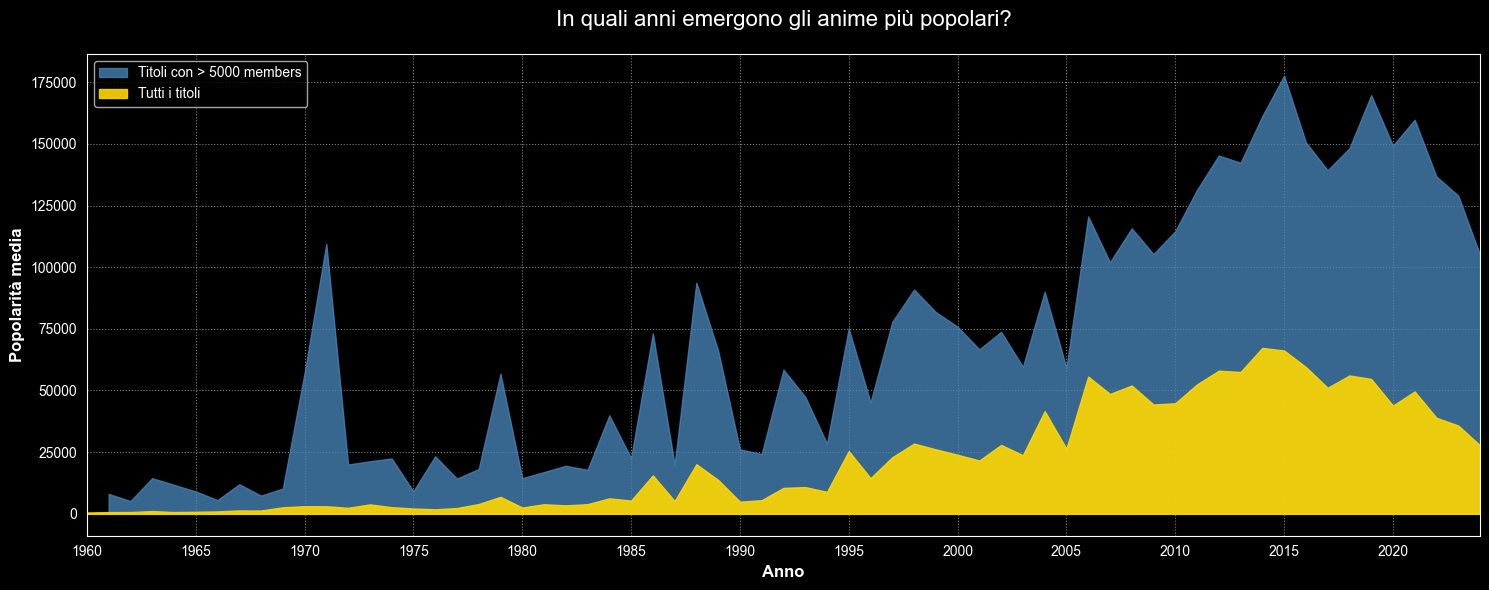

In [35]:
details = df_details.copy()

# media popolarità per anno su tutti i titoli
all_titles = (df_details.groupby('year')['members'].mean().reset_index().rename(columns={'members': 'avg_members'}))
# filtro temporale
all_titles = all_titles[(all_titles['year'] >= 1960) & (all_titles['year'] <= 2024)]
# filtro dati: solo anime con più 5000 membri
popular = (df_details[df_details['members'] > 5000].groupby('year')['members'].mean().reset_index().rename(columns={'members': 'avg_members'}))
# filtro temporale
popular = popular[(popular['year'] >= 1960) & (popular['year'] <= 2024)]

# grafico
plt.figure(figsize=(15, 6))
plt.fill_between(popular['year'], popular['avg_members'], color='steelblue', alpha=0.8, label='Titoli con > 5000 members')
plt.fill_between(all_titles['year'], all_titles['avg_members'], color='gold', alpha=0.9, label='Tutti i titoli')
plt.title('In quali anni emergono gli anime più popolari?', fontsize=16, pad=20)
plt.xlabel('Anno', fontsize=12, fontweight='bold')
plt.ylabel('Popolarità media', fontsize=12, fontweight='bold')
plt.xlim(1960, 2024)
plt.xticks(range(1960, 2025, 5))
plt.grid(linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

Il grafico mette a confronto due curve: quella blu rappresenta la popolarità media degli anime con più di 5.000 membri, mentre quella gialla mostra la media calcolata su tutti i titoli presenti nel dataset.

Una prima cosa che si nota subito è il picco intorno al 1970: la curva blu sale in modo brusco fino a circa 110.000, mentre quella gialla rimane quasi a zero. Questo non significa che l'industria fosse in grande espansione in quel periodo,  anzi, il catalogo era ancora molto limitato,  ma che quei pochi titoli riuscivano comunque a raccogliere un pubblico molto ampio. Negli anni successivi i valori scendono di nuovo, con altri picchi negli anni '80 che seguono lo stesso schema: pochi titoli molto popolari in un catalogo ancora ridotto.

La situazione cambia a partire dai primi anni 2000, dove entrambe le curve iniziano a crescere in modo più costante. La curva gialla, rimasta quasi invisibile per decenni, inizia finalmente a salire: significa che non sono più solo pochi titoli a raccogliere utenti, ma il catalogo nel suo complesso diventa più seguito. Il picco massimo si raggiunge intorno al 2014-2015, con la curva blu che supera i 175.000.

Dopo questo picco, i valori restano comunque alti, anche se con qualche oscillazione. Il calo verso il 2023-2024 è probabilmente legato al fatto che i titoli più recenti hanno avuto meno tempo per accumulare membri rispetto agli anime usciti anni prima.

### Come giudica davvero la community anime?

Dare un voto è un atto semplice, ma nasconde molto. Dietro ogni numero c'è una percezione, un'aspettativa soddisfatta o tradita. Il grafico mostra come cambiano i pattern di voto al variare della qualità dell'anime: tre fasce, tre comportamenti completamente diversi.


In [13]:
details = df_details.copy()
score_cols = df_stats.filter(regex=r"^score_\d+_votes$").columns.tolist()

# merge details con stats e rimuove righe senza score
loved = (details.merge(df_stats[["mal_id"] + score_cols], on="mal_id").dropna(subset=["score"] + score_cols))

# divide gli anime in 3 fasce di qualità
loved["score_band"] = pd.cut(loved["score"],bins=[1, 6, 8, 10],labels=["Basso (1–6)", "Medio (6–8)", "Alto (8–10)"])

# conta anime per fascia
band_counts = loved["score_band"].value_counts()

# normalizza i voti come percentuale per riga
loved_pct = loved[score_cols].div(loved[score_cols].sum(axis=1), axis=0) * 100
loved_pct["score_band"] = loved["score_band"].values

# media dei % per fascia
matrix = loved_pct.groupby("score_band", observed=True)[score_cols].mean().reset_index()

# formato lungo per plotly
matrix_melted = matrix.melt(id_vars="score_band", var_name="voto", value_name="percentuale")
matrix_melted["voto"] = matrix_melted["voto"].str.split("_").str[1].astype(int)

palette = {
    "Basso (1–6)":  "#e74c3c",
    "Medio (6–8)":  "#f39c12",
    "Alto (8–10)":  "#2ecc71"
}

fig = go.Figure()

# una traccia per ogni fascia
for band, color in palette.items():
    df_band = matrix_melted[matrix_melted["score_band"] == band]
    n = band_counts.get(band, 0)

    fig.add_trace(go.Scatter(
        x=df_band["voto"],
        y=df_band["percentuale"],
        mode="lines+markers",
        name=f"{band}  ({n:,} anime)",
        line=dict(color=color, width=3),
        marker=dict(size=8, color=color, line=dict(color="white", width=1.5)),
        fill="tozeroy",
        fillcolor=color.replace("#", "rgba(").replace("e74c3c", "231,76,60,0.12)")
                       .replace("f39c12", "243,156,18,0.12)")
                       .replace("2ecc71", "46,204,113,0.12)"),
        hovertemplate="<b>%{fullData.name}</b><br>Voto: %{x}<br>% utenti: %{y:.1f}%<extra></extra>"
    ))

# evidenzia la zona voti alti
fig.add_vrect(x0=7.5, x1=10.5, fillcolor="gold", opacity=0.04, layer="below", line_width=0)
fig.add_annotation(x=9, y=matrix_melted["percentuale"].max() * 0.95,
                   text="Zona d'eccellenza", showarrow=False,
                   font=dict(color="gold", size=11), opacity=0.6)

fig.update_layout(
    title=dict(text="Come vota la community per fascia di qualità", font=dict(size=18)),
    xaxis=dict(tickvals=list(range(1, 11)), title="Voto dato", gridcolor="rgba(255,255,255,0.07)"),
    yaxis=dict(title="% voti", gridcolor="rgba(255,255,255,0.07)", ticksuffix="%"),
    height=520, width=1200,
    legend=dict(orientation="h", y=-0.15),
    hovermode="x unified",
    plot_bgcolor="rgba(0,0,0,0)",
)
fig.show()




C'è una domanda che ogni appassionato si pone almeno una volta: quando un utente mette un voto, lo fa davvero con criterio? Il grafico risponde in modo diretto, e la risposta è più interessante di quanto si possa pensare.

Le tre curve raccontano tre comportamenti completamente diversi.

Gli anime nella fascia **bassa**, quelli che la community ha giudicato scadenti, ricevono voti sparpagliati lungo tutta la scala, con un picco curioso intorno al 7. Non è un errore: è il fenomeno del **voto di incoraggiamento**, quella tendenza a non voler essere troppo crudeli anche con un prodotto che non ha convinto. La critica esiste, ma è ammorbidita.

Gli anime **medi** seguono una curva più prevedibile: pochi voti estremi, una concentrazione nella fascia 6–8. Sono i titoli che non fanno innamorare ma nemmeno deludono, e i voti lo rispecchiano fedelmente. La community li tratta con la stessa indifferenza con cui li ha guardati.

Ma è la curva **verde** quella che vale la pena osservare. Gli anime nella fascia alta non si limitano a ricevere voti alti: ricevono voti altissimi, con una concentrazione straordinaria su 9 e 10 che non ha paragoni nelle altre fasce. Questo non è solo apprezzamento, è **devozione**. Chi guarda un anime eccellente non si ferma a un educato 8: lo promuove con il massimo, lo consiglia, lo inserisce nei preferiti.

Il dato più rivelatore è la simmetria speculare tra le due fasce estreme: mentre la curva rossa si gonfia sui voti medio-bassi, quella verde esplode sui voti massimi. La community sa distinguere, e quando qualcosa la colpisce davvero, non usa mezze misure.


### One Piece: qualità percepita e popolarità tra gli utenti


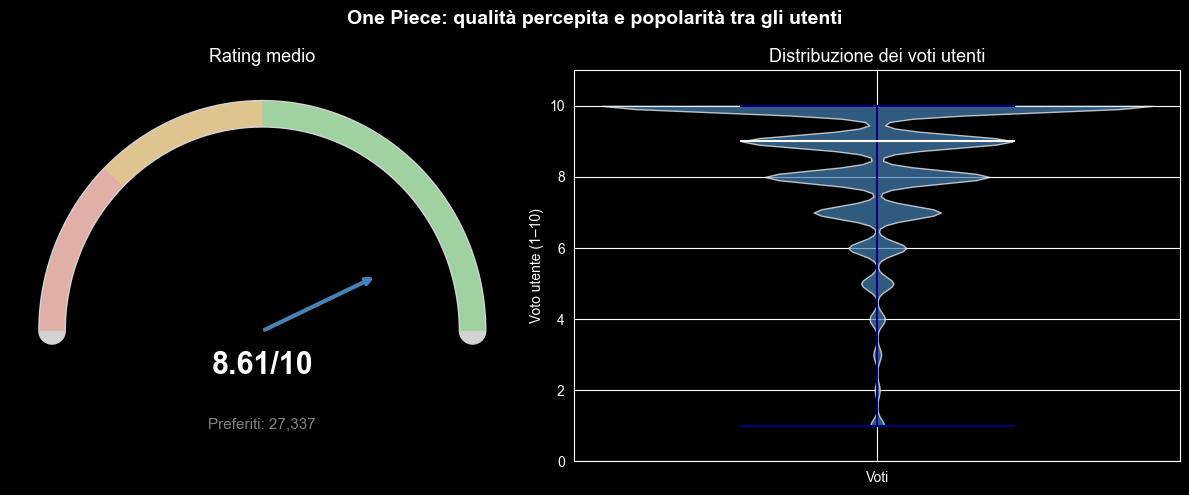

In [14]:
details = df_details.copy()
ratings = df_ratings.copy()

anime_title = 'One Piece'
mal_id = details[details['title'] == anime_title]['mal_id'].iloc[0]
# prendo solo i voti validi
anime_ratings = ratings[(ratings['anime_id'] == mal_id) & (ratings['score'] > 0)]['score']
# media dei voti
avg_user_rating = anime_ratings.mean()
# quanti utenti hanno messo One Piece nei preferiti
fav_count = favs[favs['mal_id'] == mal_id].shape[0]
fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.2])

#gauge
ax0 = fig.add_subplot(gs[0])
theta = np.linspace(0, np.pi, 300)
ax0.plot(np.cos(theta), np.sin(theta), color='lightgray', lw=20, solid_capstyle='round')

for start, end, color in [
    (0,    0.5,  '#32cd3250'),
    (0.5,  0.75, '#ffa50050'),
    (0.75, 1.0,  '#ff634750')
]:

    t = np.linspace(start * np.pi, end * np.pi, 100)
    ax0.plot(np.cos(t), np.sin(t), lw=18, color=color, solid_capstyle='butt')
angle = np.pi * (1 - avg_user_rating / 10)

ax0.annotate('', xy=(0.6 * np.cos(angle), 0.6 * np.sin(angle)), xytext=(0, 0),arrowprops=dict(arrowstyle='->', color='steelblue', lw=3))
ax0.text(0, -0.2,  f'{avg_user_rating:.2f}/10', ha='center', fontsize=22, fontweight='bold')
ax0.text(0, -0.45, f'Preferiti: {fav_count:,}', ha='center', fontsize=11, color='gray')
ax0.set_xlim(-1.2, 1.2)
ax0.set_ylim(-0.6, 1.2)
ax0.axis('off')
ax0.set_title('Rating medio', fontsize=13)

#Violin
ax1 = fig.add_subplot(gs[1])
parts = ax1.violinplot(anime_ratings, positions=[1], showmedians=True, showextrema=True)
parts['bodies'][0].set_facecolor('steelblue')
parts['bodies'][0].set_alpha(0.7)
parts['cmedians'].set_color('white')
parts['cbars'].set_color('navy')
parts['cmins'].set_color('navy')
parts['cmaxes'].set_color('navy')
ax1.set_xticks([1])
ax1.set_xticklabels(['Voti'])
ax1.set_ylabel('Voto utente (1–10)')
ax1.set_ylim(0, 11)
ax1.set_title('Distribuzione dei voti utenti', fontsize=13)
plt.suptitle('One Piece: qualità percepita e popolarità tra gli utenti', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Questo grafico analizza il caso di **One Piece**, mettendo a confronto la **qualità percepita dagli utenti** (rating medio) e la **popolarità**, misurata tramite il numero di preferenze (favs).

Il primo grafico evidenzia come One Piece presenti una popolarità estremamente elevata, normalizzata su una scala comparabile con il rating. Al contrario, il rating medio degli utenti risulta più moderato. Questo squilibrio suggerisce che la popolarità non dipende esclusivamente dal giudizio medio, ma anche da fattori come la longevità della serie, l’affezione emotiva del pubblico e l’impatto culturale nel tempo.

Il secondo grafico mostra la **distribuzione dei voti degli utenti**. Si osserva una forte concentrazione di voti alti (8–10), accompagnata però da una presenza significativa di voti bassi. Questo fenomeno è tipico delle opere molto popolari: attirano un pubblico ampio e diversificato, generando valutazioni più polarizzate.

Nel complesso, One Piece emerge come un esempio emblematico di come un anime possa essere **massicciamente seguito e amato**, pur non avendo un consenso uniforme sul piano della valutazione numerica.


### Raccomandazioni e distribuzione dei voti

In [15]:
recs = df_recommendations.copy()
ratings_clean = df_ratings.copy()

# raccomandazioni ricevute per anime
rec_count = recs['recommendation_mal_id'].value_counts().reset_index()
rec_count.columns = ['anime_id', 'n_recs']
# voto medio per anime (almeno 100 voti)
anime_scores = (ratings_clean[ratings_clean['score'] > 0].groupby('anime_id')['score'].agg(avg_score='mean', n_ratings='count').reset_index())
anime_scores = anime_scores[anime_scores['n_ratings'] >= 100]
# unione e fasce
data = anime_scores.merge(rec_count, on='anime_id', how='inner')
bins = [0, 5, 20, 50, float('inf')]
tier_labels = ['1–5', '6–20', '21–50', '51+']
data['rec_tier'] = pd.cut(data['n_recs'], bins=bins, labels=tier_labels)

# voto medio e conteggio per fascia
summary = (data.groupby('rec_tier', observed=True)['avg_score'].agg(media='mean', n_anime='count').reset_index())
summary['etichetta'] = summary.apply(lambda r: f"{r['media']:.2f} ({int(r['n_anime'])} anime)", axis=1)
# creazione grafico con Plotly
fig = px.line(summary, x='rec_tier', y='media', markers=True, text='etichetta',
    title="Gli anime più raccomandati sono anche i più apprezzati",
    labels={'rec_tier': 'Raccomandazioni ricevute', 'media': 'Voto medio'},
    custom_data=['n_anime'])
fig.update_traces(
    marker=dict(size=10), line=dict(width=2.5, color='steelblue'),
    textposition='top center',
    hovertemplate='<b>%{x} raccomandazioni</b><br>'
                  'Voto medio: %{y:.2f}<br>'
                  'Anime: %{customdata[0]}<extra></extra>'
)
fig.update_layout(
    yaxis=dict(range=[5.8, 8.1]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Quando il passaparola diventa dato

C'è un gesto semplice che ogni appassionato di anime conosce bene: "guardati questo, fidati". Una raccomandazione non è solo un suggerimento, è una forma di responsabilità. Chi la fa ci mette la faccia, sta dicendo che quell'anime vale il tempo di un'altra persona. E il grafico che emerge dai dati lo conferma in modo quasi sorprendente nella sua linearità.

La linea sale. Senza eccezioni, senza inversioni di tendenza. Più un anime viene raccomandato, più alto è il suo voto medio. Gli anime nella fascia 1–5 raccomandazioni si fermano a 6.22, una valutazione nella media, niente di memorabile. Ma salendo di fascia in fascia, qualcosa cambia: a 6–20 raccomandazioni si superano i 7 punti, e gli anime con 51 o più raccomandazioni arrivano a 7.56.

Non è solo una correlazione statistica. È la logica del passaparola: le persone raccomandano ciò che le ha colpite davvero, non ciò che è semplicemente "carino". Un anime che rimbalza di mano in mano tra gli utenti è un anime che ha lasciato il segno che ha sorpreso, emozionato, fatto discutere. I titoli che raccolgono decine di raccomandazioni non ci finiscono per caso: ci finiscono perché qualcuno, finita la visione, ha sentito l'urgenza di dirlo a qualcun altro.

In questo senso, le raccomandazioni funzionano come un filtro collettivo di qualità,forse il più onesto che esista. Non viene assegnato da una redazione, non segue criteri commerciali, non dipende dal budget della campagna marketing. È semplicemente la somma di migliaia di persone che hanno deciso, liberamente, che quell'anime meritava di essere condiviso

## 5. I PERSONAGGI

Dopo aver osservato gli anime più popolari, il passo successivo è capire **dove si concentra l’attenzione dei fan**.

### Personaggi principali e secondari: quantità e notorietà a confronto

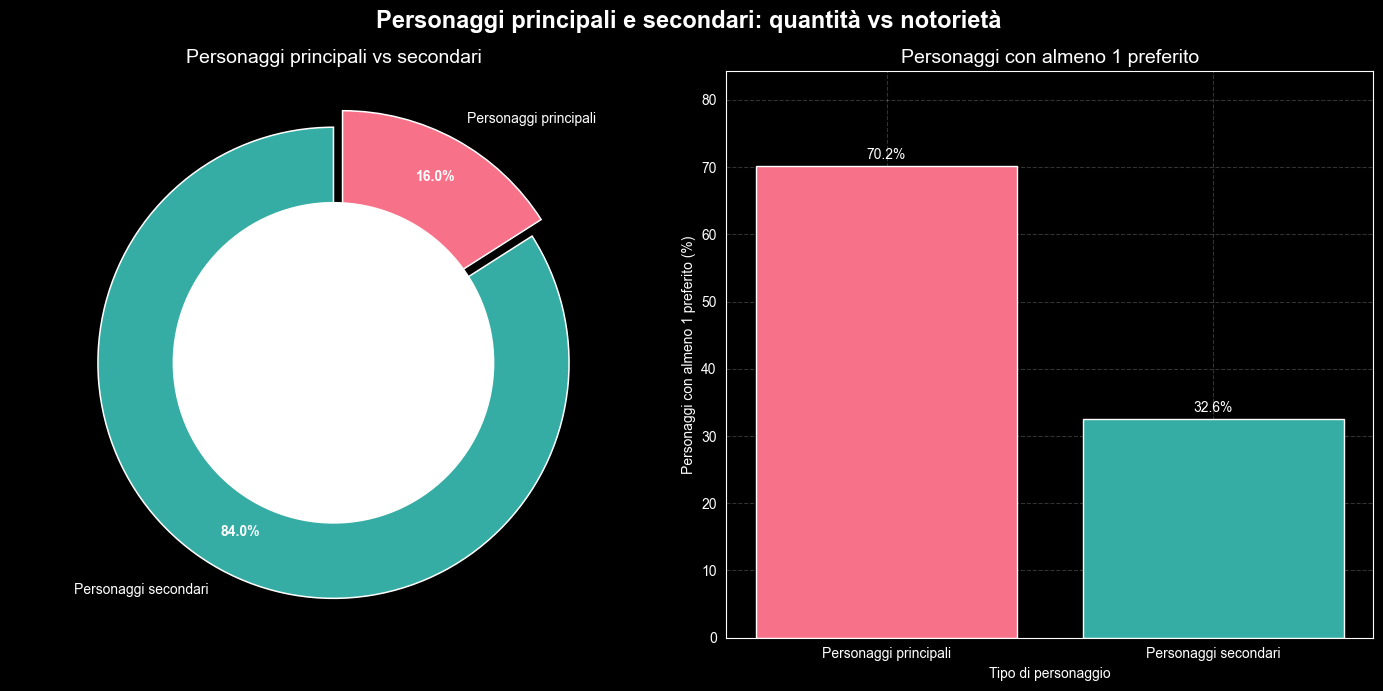

In [16]:
# preparazione dati
character_popularity = (
    df_characters_anime_works
    .loc[lambda df: df["role"].isin(["Main", "Supporting"]), ["character_mal_id", "role"]]
    .drop_duplicates()
    .groupby("character_mal_id")
    .filter(lambda x: x["role"].nunique() == 1)
    .drop_duplicates("character_mal_id")
    .merge(df_characters[["character_mal_id", "favorites"]], on="character_mal_id")
)
labels = {"Main": "Personaggi principali", "Supporting": "Personaggi secondari"}
order = ["Personaggi principali", "Personaggi secondari"]
character_popularity["role_group"] = character_popularity["role"].replace(labels)
character_popularity["has_favorites"] = character_popularity["favorites"] > 0
# tabelle
main_support_table = (character_popularity.groupby("role_group")["character_mal_id"].nunique().reindex(order))
popularity_table = (character_popularity.groupby("role_group").agg(total=("character_mal_id", "nunique"),with_favourites=("has_favorites", "sum")).reindex(order))
popularity_table["share"] = (popularity_table["with_favourites"] / popularity_table["total"] * 100).round(1)
# grafico
plt.figure(figsize=(14, 7))
colors = sns.color_palette("husl", 2)
plt.subplot(1, 2, 1)
wedges, texts, autotexts = plt.pie(
    main_support_table,
    labels=main_support_table.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    explode=[0.08, 0],
    pctdistance=0.82,
    wedgeprops={"edgecolor": "white", "linewidth": 1.1}
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")
plt.gca().add_artist(plt.Circle((0, 0), 0.68, fc="white"))
plt.title("Personaggi principali vs secondari", fontsize=14)
plt.axis("equal")
plt.subplot(1, 2, 2)
bars = plt.bar(popularity_table.index, popularity_table["share"], color=colors)
for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}%", ha="center", fontsize=10)
plt.title("Personaggi con almeno 1 preferito", fontsize=14)
plt.xlabel("Tipo di personaggio")
plt.ylabel("Personaggi con almeno 1 preferito (%)")
plt.ylim(0, popularity_table["share"].max() * 1.2)
plt.grid(True, alpha=0.2, linestyle='--')
plt.suptitle("Personaggi principali e secondari: quantità vs notorietà", fontsize=17, fontweight="bold")
plt.tight_layout()
plt.show()

l grafico racconta due storie parallele sui personaggi anime.

A sinistra, i numeri: solo il 16% dei personaggi sono protagonisti, mentre l'84% sono figure secondarie. L'universo degli anime è **popolato principalmente da personaggi di contorno**, necessari a costruire il mondo narrativo intorno ai protagonisti.

A destra, la notorietà: il 70% dei personaggi principali ha ricevuto almeno un preferito dagli utenti, contro solo il 32.6% dei secondari. Nonostante siano in minoranza, **i protagonisti riescono quasi sempre a lasciare il segno.**

I personaggi secondari possono essere più numerosi, ma i **protagonisti tendono ad avere maggiore visibilità e a costruire un legame più diretto con i fan**.

## 6. I DOPPIATORI E LINGUE: LE VOCI DIETRO GLI ANIME

Un personaggio non vive solo attraverso il disegno o la storia: **vive anche attraverso la voce**.
Il doppiaggio dà identità ai personaggi, li rende riconoscibili e permette agli anime di arrivare a pubblici diversi.

### Distribuzione dei personaggi doppiati tra i doppiatori

In [17]:
# preparazione dati
voice_works = df_person_voice_works.copy()
voice_counts = (
    voice_works.groupby("person_mal_id")["character_mal_id"]
    .nunique()
    .reset_index(name="characters")
)
voice_counts["range"] = pd.cut(
    voice_counts["characters"],
    bins=[0, 1, 5, 10, 25, 50, 100, 200, 600],
    labels=["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-200", "200+"]
)
range_counts = (
    voice_counts["range"]
    .value_counts()
    .sort_index()
    .reset_index()
)
range_counts.columns = ["range", "voice_actors"]
palette = sns.color_palette("husl", len(range_counts)).as_hex()

# grafico
fig = px.bar(
    range_counts,
    x="range",
    y="voice_actors",
    text="voice_actors",
    title="Distribuzione dei personaggi doppiati per doppiatore",
    labels={"range": "Personaggi doppiati", "voice_actors": "Numero di doppiatori"}
)
fig.update_traces(
    marker_color=palette,
    textposition="outside"
)
fig.update_layout(
    template="plotly_white",
    showlegend=False,
    width=1200,
    height=500,
    yaxis_type="log"
)
fig.show()

Il grafico mostra come si distribuiscono i doppiatori in base al numero di **personaggi distinti interpretati**. La distribuzione è fortemente sbilanciata: la maggior parte dei doppiatori compare in poche produzioni o interpreta pochi ruoli, mentre solo una piccola minoranza accumula un numero molto elevato di personaggi nel corso del tempo.

Questo andamento mostra che tanti doppiatori hanno una presenza limitata nel dataset, mentre pochi professionisti ricorrenti concentrano una parte importante dell’esperienza di doppiaggio. Dunque, il settore non sembra distribuito in modo uniforme: esiste un ampio gruppo di voci occasionali e un gruppo ristretto di doppiatori molto presenti.

Il risultato è interessante perché sposta l’attenzione dalla semplice classifica dei nomi più famosi alla **struttura generale del lavoro di doppiaggio**. Invece di osservare solo i primi dieci doppiatori, il grafico considera l’intero insieme dei professionisti disponibili e mostra come la partecipazione ai ruoli sia concentrata in modo molto diseguale.

> **Nota sui dati:** su 22.275 doppiatori, il 69.8% ha interpretato al massimo 10 personaggi, mentre solo il 3% supera i 100 ruoli. L’asse verticale è in scala logaritmica per rendere visibili anche le categorie meno frequenti.

Il doppiaggio permette agli anime di superare i confini linguistici e raggiungere community diverse.

### Oltre i confini del Giappone: il doppiaggio come mappa del mondo

In [18]:
voice = df_person_voice_works.copy()
lang_stats = (voice.groupby("language")["anime_mal_id"].nunique().reset_index(name="anime_count").sort_values("anime_count", ascending=False))
# figura
fig = px.treemap(
    lang_stats,
    path=["language"],
    values="anime_count",
    color="anime_count",
    color_continuous_scale="Purples",
    title="Lingue dei doppiaggi negli anime",
)
fig.update_traces(
    textinfo="label+value+percent root",
    textfont_size=14,
    hovertemplate="<b>%{label}</b><br>Anime: %{value:,}<br>%{percentRoot:.1%}<extra></extra>",
)
fig.update_layout(
    height=520,
    margin=dict(t=50, l=10, r=10, b=10),
    coloraxis_colorbar=dict(title="N. anime"),
)
fig.show()

Il treemap fotografa una realtà spesso sottovalutata: il doppiaggio degli anime non è un fenomeno solo giapponese-americano. È un'industria distribuita su scala globale, e il grafico lo mostra senza ambiguità.

Il giapponese occupa il blocco più grande, è la lingua originale, quella da cui tutto parte. L'inglese è secondo, con un distacco netto ma non abissale: conferma il peso del mercato nordamericano nella catena di distribuzione internazionale.

Quello che colpisce davvero è il blocco europeo. Francese e spagnolo si posizionano subito dopo l'inglese, davanti all'italiano e al tedesco. La Francia, in particolare, è da decenni uno dei mercati di doppiaggio anime più attivi al mondo, un fatto che i dati rendono visibile in modo diretto.

Il dato più inaspettato, però, è il portoghese brasiliano: supera l'italiano e si affianca allo spagnolo. Per un paese geograficamente lontano dall'Asia, è un segnale preciso di quanto il mercato brasiliano investa nella localizzazione degli anime.

Infine, coreano e mandarino: presenti, ma con numeri sorprendentemente contenuti rispetto alla dimensione delle rispettive fanbase. Una possibile lettura è che quelle community preferiscano ancora il consumo in lingua originale con sottotitoli, un dato che il grafico non mostra direttamente, ma che il confronto fa intuire.

## 7. Community anime nel mondo

Gli anime non crescono soltanto come produzione: crescono anche attraverso le persone che li guardano, li commentano, li valutano e li inseriscono nelle proprie liste.
Dopo aver seguito titoli, personaggi e doppiatori, la storia si sposta quindi sulla community: dove si concentra e come si è sviluppata nel tempo.

### Dov'è concentrata la community anime?

In [19]:
profiles = df_profiles.copy()

# estrazione del paese
profiles["country"] = profiles["location"].str.split(",").str[-1].str.strip()
# nomralizzazione dei nomi
profiles["country"] = (
    profiles["country"]
    .replace(utils.COUNTRY_FIX)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# conversione in ISO3
profiles["iso3"] = profiles["country"].apply(utils.to_iso3)

# controlli per vedere quanti utenti hanno un paese riconoscito
u_total = profiles["username"].nunique()
u_loc = profiles.loc[profiles["location"].notna(), "username"].nunique()
u_iso = profiles.loc[profiles["iso3"].notna(), "username"].nunique()

print(f"Unique users: {u_total:,}")
print(f"Users with location: {u_loc:,} ({u_loc/u_total:.1%})")
print(f"Users mapped to ISO3: {u_iso:,} ({u_iso/u_total:.1%} of total)")
print(f"Coverage among users with location: {u_iso/u_loc:.1%}")

# conteggio utenti unici per paese
country_counts = (
    profiles.dropna(subset=["iso3"])
    .groupby("iso3")["username"]
    .nunique()
    .reset_index(name="n_users")
)
#log_10 riduce il divario tra paesi con molti e pochi utenti
country_counts["log_users"] = np.log10(country_counts["n_users"] + 1)

# mappa
fig = px.choropleth(
    country_counts,
    locations="iso3",
    color="log_users",
    hover_data={"n_users": True, "log_users": ":.2f"},
    title="Dov'è concentrata la community anime?",
    color_continuous_scale=px.colors.sequential.Plasma
)
fig.update_layout(
    width=1200,
    height=600,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(color="black")
)
fig.update_coloraxes(
    colorbar_title=dict(text="log10(users)", font=dict(color="black")),
    colorbar_tickfont=dict(color="black")
)
fig.update_geos(
    showland=True,
    landcolor="lightgrey",
    showocean=True,
    oceancolor="#e6f2ff"
)
fig.show()

La mappa allarga lo sguardo e mostra la presenza della community su scala mondiale.

Questo grafico  fa capire bene quanto gli anime siano usciti dal loro contesto di origine e siano diventati un interesse condiviso a livello internazionale. Non si parla più di un fenomeno solo giapponese, ma di una **community molto ampia e diffusa**.


> **Nota sui dati:** i paesi sono stati ricavati dal campo **location** dei profili utente, normalizzato e convertito in codice ISO3. Su 337154 utenti unici, tutti presentavano una localizzazione valida e sono stati mappati correttamente (copertura 100%). La mappa mostra il numero di utenti unici per paese su scala logaritmica log10(user + 1), così da rendere leggibili anche paesi con meno utenti


### Concentrazione geografica della community

In [20]:
profiles = df_profiles.copy()
profiles["country"] = (
    profiles["location"].str.split(",").str[-1].str.strip()
    .replace(utils.COUNTRY_FIX).str.strip()
)
profiles_valid = profiles[profiles["country"].notna() & (profiles["country"] != "")]
country_counts = (
    profiles_valid.groupby("country")["username"]
    .nunique().sort_values(ascending=False)
    .reset_index(name="n_users")
)

fig = px.treemap(
    country_counts, path=["country"], values="n_users", color="n_users",
    color_continuous_scale="Viridis",
    title="Dove vive la community anime? Distribuzione globale degli utenti",
    labels={"n_users": "Utenti"}
)
fig.update_layout(template="plotly_white", width=1200, height=600)
fig.show()

Il treemap mostra come gli utenti della **community anime** si distribuiscono tra i diversi paesi. La dimensione di ogni rettangolo è proporzionale al numero di utenti: per questo paesi come **Japan** e **United States** occupano una parte molto ampia della visualizzazione, mentre gli altri paesi appaiono progressivamente più piccoli.

Il risultato evidenzia una community **internazionale**, ma allo stesso tempo **fortemente concentrata**. La presenza di molti paesi mostra che l’interesse per gli anime non è limitato a una sola area geografica; tuttavia, la distribuzione non è uniforme, perché pochi poli raccolgono una quota molto alta degli utenti. Questo permette di leggere la community come un fenomeno globale, ma con alcuni centri principali di partecipazione molto più visibili degli altri.

Rispetto a una semplice classifica, il treemap aiuta a visualizzare meglio il peso relativo dei paesi: non mostra solo chi ha più utenti, ma fa percepire immediatamente quanto spazio occupano i principali paesi rispetto al resto della community.

### Crescita della community nel tempo a livello globale

In [21]:
df = df_profiles.copy()
df["joined"] = pd.to_datetime(df["joined"], errors="coerce")
df["joined_year"] = df["joined"].dt.year
# conto i nuovi utenti per anno
users_per_year = (
    df.dropna(subset=["joined_year"])
    .groupby("joined_year")["username"]
    .nunique()
    .reset_index(name="new_users")
)
users_per_year["joined_year"] = users_per_year["joined_year"].astype(int)
users_per_year = users_per_year[users_per_year["joined_year"].between(2005, 2024)]

# line chart globale + cenni storici
fig = px.line(
    users_per_year,
    x="joined_year",
    y="new_users",
    markers=True,
    title="Nuovi utenti registrati per anno",
    labels={"joined_year": "Anno", "new_users": "Nuovi utenti"}
)
#periodi storici + rilevanti
fig.add_vrect(x0=2008, x1=2009, fillcolor="lightgrey", opacity=0.2, line_width=0)
fig.add_vrect(x0=2020, x1=2022, fillcolor="lightgrey", opacity=0.2, line_width=0)

fig.add_annotation(x=2008.5, y=users_per_year["new_users"].max() * 0.95,
                   text="Crisi finanziaria", showarrow=False)
fig.add_annotation(x=2021, y=users_per_year["new_users"].max() * 0.95,
                   text="Pandemia COVID-19", showarrow=False)
fig.update_layout(width=1200, height=600)
fig.show()

La crescita degli utenti registrati mostra come la community online si sia allargata nel tempo.

Il picco durante il periodo pandemico è il dato più evidente: il 2020-2021 ha registrato un afflusso di nuovi utenti senza precedenti, probabilmente legato all'aumento del tempo trascorso online durante i lockdown. Negli anni successivi la crescita rallenta, tornando su livelli più in linea con il trend precedente alla pandemia.




> **Nota sui dati:** 13.848 utenti con anno di iscrizione fuori dall’intervallo 2005–2024 e 1.676 utenti con data non leggibile sono stati esclusi dal grafico. La curva rappresenta quindi il 95,4% degli utenti totali.

Dopo aver osservato la crescita complessiva della community, possiamo guardare più da vicino chi compone questa community, analizzando alcune caratteristiche dichiarate dagli utenti nei loro profili.

###  Genere più diffuso nella community anime

In [22]:
# preparazione dati
profiles_gender = df_profiles.copy()
profiles_gender["gender"] = (
    profiles_gender["gender"]
    .fillna("Non dichiarato")
    .replace("", "Non dichiarato")
    .str.strip()
    .replace({
        "Female": "Femmina",
        "Male": "Maschio",
        "Non-Binary": "Non binario",
        "Not declared": "Non dichiarato"
    })
)
gender_counts = (
    profiles_gender["gender"]
    .value_counts()
    .reset_index(name="count")
    .rename(columns={"index": "gender"})
)

# donut chart con Plotly
fig = px.pie(
    gender_counts,
    values="count",
    names="gender",
    hole=0.5,
    title="Distribuzione del genere degli utenti",
    labels={"gender": "Genere", "count": "Utenti"},
    color="gender",
    color_discrete_map={
        "Femmina": "#e76f51",
        "Maschio": "#457b9d",
        "Non binario": "#2a9d8f",
        "Non dichiarato": "#adb5bd"
    }
)

fig.update_traces(textposition="inside", textinfo="percent+label")
fig.update_layout(width=1200, height=600)
fig.show()

Il genere dichiarato offre una prima lettura per capire come è composta la community anime, ma va interpretato con cautela: non tutti gli utenti scelgono di condividere questa informazione.

La categoria più rappresentata è "Non dichiarato" (50.7%), seguita da Maschio (35.8%) e Femmina (12.3%), il restante 1.25% si identifica come non Binario, ovvero utenti identificati con un genere che non rientra in Machio o Femmina.



> **Nota sui dati:** le categorie di genere sono quelle dichiarate direttamente dagli utenti sulla piattaforma MyAnimeList e non sono state modificate. I valori mancanti o vuoti sono stati raggruppati nella categoria "Non dichiarato". Il grafico considera tutti i 335.478 profili utente presenti nel dataset.

## 8. PERSONE E RUOLI NELL'INDUSTRIA ANIME

Dietro ogni anime non ci sono solo personaggi e doppiatori, ma anche una rete più ampia di persone: autori, registi, musicisti, produttori e molte altre figure professionali.

### Distribuzione geografica delle figure professionali dell’industria anime

In [23]:
country_counts = df_person_details.copy()
country_counts["country"] = (
    country_counts["relevant_location"]
    .astype("string")
    .str.split(",").str[-1]
    .str.strip()
    .str.title()
    .replace(utils.COUNTRY_FIX)
    .str.strip()
)
country_counts = (
    country_counts.groupby("country")["person_mal_id"]
    .nunique()
    .reset_index(name="n_people")
)
country_counts["iso3"] = country_counts["country"].apply(utils.to_iso3)
present_df = country_counts.dropna(subset=["iso3"]).copy()
present_df["log_people"] = np.log10(present_df["n_people"] + 1)

fig = px.choropleth(
    present_df,
    locations="iso3",
    color="log_people",
    hover_name="country",
    hover_data={"n_people": True, "log_people": False},
    title="Da quali paesi provengono i produttori degli anime?",
    color_continuous_scale=px.colors.sequential.Plasma,
    labels={"log_people": "log10(persone)"}
)
fig.update_geos(
    showland=True, landcolor="lightgrey",
    showcountries=True, countrycolor="white",
    showocean=True, oceancolor="#e6f2fb",
    showframe=False
)
fig.update_layout(
    width=1200, height=600,
    paper_bgcolor="white",
    font=dict(color="black")
)
fig.show()

Il grafico mostra la distribuzione geografica delle **persone coinvolte nell’industria anime**. La mappa non rappresenta quindi il pubblico, ma il lato produttivo e professionale: persone associate agli anime attraverso ruoli, credits o informazioni presenti.

La concentrazione più forte si osserva in **Giappone** e **Stati Uniti**, che risultano i due poli principali. Questo dato è interessante perché conferma la centralità del Giappone nell’industria anime, ma mostra anche come il settore non sia isolato: altri paesi, soprattutto in **Europa** e in alcune aree extra-asiatiche, contribuiscono alla rete di persone collegate alla produzione e alla distribuzione degli anime.

Questo passaggio permette di distinguere due livelli diversi dell’analisi: da un lato la **diffusione globale della community**, osservata attraverso gli utenti; dall’altro la **distribuzione geografica delle figure professionali**, che segue logiche più concentrate. In questo modo emerge una differenza importante: gli anime sono consumati da una community internazionale, ma le persone coinvolte nel settore risultano concentrate in un numero più ristretto di paesi.

**Nota sui dati:** i paesi sono stati estratti dal campo `relevant_location`, normalizzati tramite `COUNTRY_FIX` e convertiti in codici ISO3 tramite `to_iso3()`. La mappa considera solo le persone con una localizzazione riconducibile a un paese riconosciuto. Il colore usa una scala logaritmica per rendere leggibili anche i paesi con valori più bassi, evitando che i paesi con molti professionisti dominino completamente la visualizzazione.

### Distribuzione Generazionale delle persone che lavorano nell'industria anime

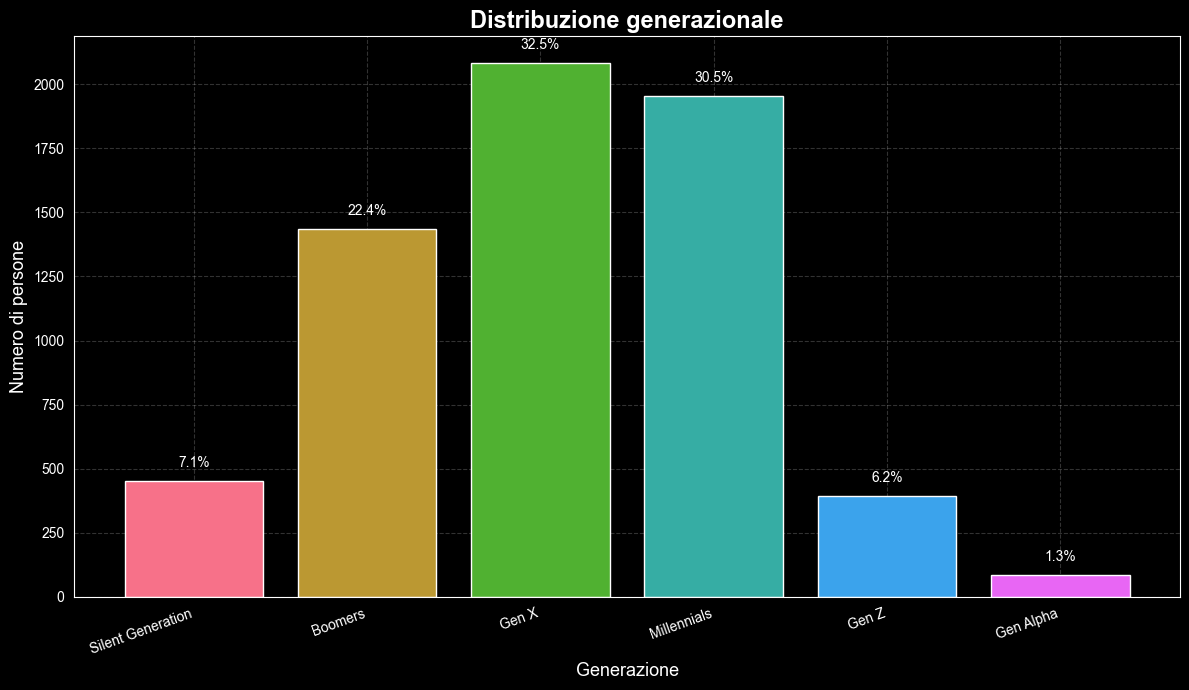

In [24]:
# preparazione dati
staff = (
    df_person_anime_works[["person_mal_id"]]
    .drop_duplicates()
    .merge(
        df_person_details[["person_mal_id", "birthday"]],
        on="person_mal_id",
        how="left"
    )
)
staff["birth_year"] = pd.to_datetime(
    staff["birthday"], errors="coerce",  utc=True
).dt.year
staff.loc[~staff["birth_year"].between(1900, 2024), "birth_year"] = pd.NA
labels = [
    "Silent Generation", "Boomers", "Gen X", "Millennials", "Gen Z", "Gen Alpha"]

staff["generation"] = pd.cut(
    staff["birth_year"],
    bins=[-np.inf, 1945, 1964, 1980, 1996, 2012, 2024],
    labels=labels
)
gen_counts = (
    staff["generation"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis("generation")
    .reset_index(name="count")
)
gen_counts["share"] = (
    gen_counts["count"] / gen_counts["count"].sum() * 100
).round(1)
# grafico
plt.figure(figsize=(12, 7))
colors = sns.color_palette("husl", n_colors=len(gen_counts))
bars = plt.bar(
    gen_counts["generation"],
    gen_counts["count"],
    color=colors
)
for bar, share in zip(bars, gen_counts["share"]):
    height = bar.get_height()
    plt.text(
    bar.get_x() + bar.get_width()/2.,
    height + gen_counts["count"].max() * 0.02,
    f'{share}%',
    ha='center',
    va='bottom',
    fontsize=10
)
plt.xlabel("Generazione", fontsize=13)
plt.ylabel("Numero di persone", fontsize=13)
plt.title("Distribuzione generazionale", fontsize=17, fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.grid(True, alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

Il grafico mostra la **distribuzione generazionale delle persone presenti nei credits degli anime**. Le generazioni più rappresentate sono **Gen X** e **Millennials**, seguite dai **Boomers**. Questo suggerisce che una parte consistente delle figure professionali registrate nel dataset appartiene a generazioni che hanno costruito la propria carriera durante la forte espansione dell’industria anime tra gli anni ’80, ’90 e 2000.

La presenza più contenuta di **Gen Z** e **Gen Alpha** non va interpretata come scarso interesse delle nuove generazioni, ma come un effetto naturale dell’età e del percorso professionale: per entrare nei credits di un anime serve tempo, esperienza e una carriera già avviata. Al contrario, le generazioni precedenti hanno avuto più anni per accumulare ruoli, collaborazioni e partecipazioni registrate nel dataset.

Questo grafico aggiunge quindi una dimensione temporale all’analisi dell’industria: non osserviamo solo **dove** si concentrano le figure professionali, ma anche **quali generazioni** hanno contribuito maggiormente alla costruzione del settore.

**Nota sui dati:** su **26.236 persone** presenti nei credits anime, solo **6.409** avevano un anno di nascita valido compreso tra **1900 e 2024**. Il grafico rappresenta quindi circa il **24,4%** del totale. Le persone senza data di nascita disponibile o con valori non validi sono state escluse dall’analisi.

### Gli architetti dell'industria: chi produce di più e chi produce meglio?

In [25]:
studios = df_details.copy()
studios["studio"] = studios["studios"].apply(
    lambda s: ast.literal_eval(s)[0] if pd.notna(s) and ast.literal_eval(s) else None
)
studios["score"] = pd.to_numeric(studios["score"], errors="coerce")

studio_stats = (
    studios.dropna(subset=["studio", "score"])
    .query("scored_by >= 500")
    .groupby("studio")
    .filter(lambda x: len(x) >= 50)
    .groupby("studio")
    .agg(avg_score=("score","mean"), total_anime=("mal_id","count"))
    .reset_index()
)

fig = px.treemap(
    studio_stats,
    path=["studio"],
    values="total_anime",
    color="avg_score",
    color_continuous_scale="YlOrRd",
    hover_data={"avg_score": ":.2f", "total_anime": True},
    labels={"total_anime": "Anime prodotti", "avg_score": "Score medio"},
    title="Studi con almeno 50 anime"
)

fig.show()

Dietro ogni anime c'è uno studio. Ma non tutti gli studi sono uguali: alcuni costruiscono empire da centinaia di titoli, altri scelgono la strada della qualità rigorosa, producendo poco ma lasciando il segno. Alcuni esistono da decenni e hanno attraversato l'intera storia del medium, altri sono nati di recente e si sono imposti con una velocità sorprendente.

Questa mappa racconta esattamente questo: *la dimensione di ogni blocco* dice quanti anime ha prodotto quello studio nel corso della sua storia, *il colore* dice quanto bene — dal giallo tenue di chi fatica a tenersi sopra la media, al rosso intenso di chi ha saputo costruire una reputazione solida titolo dopo titolo, anno dopo anno.

Il dato più immediato è la *concentrazione del mercato*: Toei Animation, J.C.Staff e Sunrise dominano per volume, avendo sfornato centinaia di titoli in decenni di attività ininterrotta. Sono le fabbriche dell'industria, motori instancabili che alimentano il palinsesto stagionale e tengono in vita franchise che durano da generazioni. Dragon Ball, One Piece, Gundam: dietro i titoli più longevi della storia degli anime ci sono sempre questi nomi.

Ma il volume racconta solo metà della storia. Perché se si guarda il colore invece che la dimensione, emerge un quadro completamente diverso. Studi come *Kyoto Animation* e *ufotable* occupano blocchi più piccoli sul canvas, eppure brillano con i toni più intensi: meno anime prodotti, ma ogni titolo costruito con una cura artigianale che si riflette direttamente nei punteggi degli utenti. KyoAni con Violet Evergarden e A Silent Voice, ufotable con Demon Slayer e Fate/Zero — studi che hanno scelto di scommettere sulla qualità invece che sulla quantità, e che quella scommessa l'hanno vinta.

Nel mezzo si trovano gli studi che hanno cercato di fare entrambe le cose: *Madhouse, **Bones, **Production I.G* — nomi che portano con sé decenni di titoli amati, da Death Note a Fullmetal Alchemist, da Ghost in the Shell a Haikyuu. Non sono né le fabbriche né i laboratori artigianali: sono qualcosa di più difficile da definire, studi che hanno saputo alternare grandi successi a produzioni più ordinarie, costruendo comunque una identità riconoscibile.

La vera domanda che questa mappa pone non è tecnica, è strategica: *vale la pena produrre tanto o produrre bene?* I dati sembrano suggerire che le due strade non si escludono, ma che chi ha scelto la qualità come priorità ha lasciato un'impronta culturale spesso più profonda di chi ha puntato tutto sul volume.

### Volume, qualità e impatto: tre dimensioni di uno stesso racconto

In [26]:
studios = df_details.copy()
studios["studio"] = studios["studios"].apply(
    lambda s: ast.literal_eval(s)[0] if pd.notna(s) and ast.literal_eval(s) else None
)
studios["score"]   = pd.to_numeric(studios["score"],   errors="coerce")
studios["members"] = pd.to_numeric(studios["members"], errors="coerce")

studios_filtered = (
    studios.dropna(subset=["studio", "score"])
    .query("scored_by >= 500")
    .groupby("studio")
    .filter(lambda x: len(x) >= 50)
)

best_anime = (
    studios_filtered
    .sort_values("members", ascending=False)
    .groupby("studio").first().reset_index()
    [["studio", "title", "members"]]
    .rename(columns={"title": "top_anime", "members": "top_members"})
)

studio_stats = (
    studios_filtered
    .groupby("studio")
    .agg(avg_score=("score","mean"), total_anime=("mal_id","count"))
    .reset_index()
    .merge(best_anime, on="studio")
)

studio_stats["top_members"] = studio_stats["top_members"].astype(int)

fig = px.scatter(
    studio_stats,
    x="total_anime",
    y="avg_score",
    size="top_members",
    size_max=60,
    color="avg_score",
    color_continuous_scale="YlOrRd",
    hover_name="studio",
    hover_data={"top_anime": True, "top_members": ":,", "total_anime": True, "avg_score": ":.2f"},
    labels={
        "total_anime": "Anime prodotti",
        "avg_score":   "Score medio",
        "top_anime":   "Anime più famoso",
        "top_members": "Utenti MAL (anime top)",
    },
    title="Studi anime — dimensione pallina = popolarità dell'anime più famoso"
)
fig.update_layout(coloraxis_showscale=False, height=700, width=1200)

fig.show()

Se la mappa precedente mostrava il territorio, questo grafico ne rivela la profondità. Ogni pallina è uno studio, ma stavolta tre variabili parlano contemporaneamente: *quanti anime ha prodotto* (asse orizzontale), *quanto bene in media* (asse verticale) e *quanto ha saputo colpire il grande pubblico* con il suo titolo più famoso (dimensione della pallina).

La prima cosa che salta all'occhio è la *concentrazione a sinistra*: la maggior parte degli studi si affolla nella zona dei 50-150 anime prodotti, con punteggi che oscillano tra il 6.5 e il 7.4. È la fascia degli studi professionali e solidi, capaci di lavorare con continuità senza mai raggiungere vette straordinarie. Producono, consegnano, tornano a produrre.

Ma sono le eccezioni a raccontare la storia più interessante. In alto a sinistra si trovano gli studi che hanno scelto la strada stretta: pochi titoli, altissima qualità media. *Kyoto Animation* è il caso più emblematico, un catalogo contenuto rispetto ai giganti del settore, ma un punteggio medio che pochi riescono ad avvicinare. La loro filosofia è nota nell'industria: nessun titolo viene accettato se non si crede di poterlo fare al massimo delle proprie capacità.

Spostandosi verso destra, il volume cresce ma la qualità tende a scendere. È la legge dei grandi numeri applicata all'animazione: più si produce, più difficile diventa mantenere uno standard elevato su ogni singolo titolo. *Toei Animation*, con oltre 600 anime all'attivo, ha scritto la storia del medium ma porta con sé anche anni di produzioni meno ispirate, che abbassano inevitabilmente la media.

La dimensione delle palline aggiunge un'ultima lettura, forse la più sorprendente: *l'impatto culturale non segue né la quantità né la qualità media. Studi con punteggi medi nella norma hanno prodotto i titoli più seguiti di sempre. *Death Note per Madhouse, Shingeki no Kyojin per Wit Studio — anime che hanno superato la community degli appassionati e sono diventati fenomeni globali, indipendentemente dal catalogo dello studio che li ha creati.

Tre numeri, tre storie. E insieme, il ritratto più onesto di come funziona davvero questa industria.

### Gli anime più popolari hanno una produzione più complessa?

In [27]:
works = df_person_anime_works.copy()
works["role"] = works["position"].str.split("(").str[0].str.strip()

anime_roles = (
    works.groupby("anime_mal_id")
    .agg(people=("person_mal_id", "nunique"), roles=("role", "nunique"))
    .reset_index()
)

anime_analysis = (
    anime_roles.merge(
        df_details[["mal_id", "favorites"]].rename(columns={"mal_id": "anime_mal_id"}),
        on="anime_mal_id", how="inner"
    )
    .dropna(subset=["favorites"])
    .query("favorites > 0")  # rimuove anime senza favorites
)

anime_analysis["popularity_range"] = pd.cut(
    anime_analysis["favorites"],
    bins=[0, 10, 100, 1000, anime_analysis["favorites"].max()],
    labels=["1-10", "11-100", "101-1k", "1k+"]
)

plot_data = (
    anime_analysis.groupby("popularity_range", observed=True)
    .agg(avg_people=("people", "mean"), avg_roles=("roles", "mean"))
    .reset_index()
    .melt(id_vars="popularity_range", var_name="metric", value_name="value")
    .replace({"avg_people": "Persone coinvolte", "avg_roles": "Ruoli diversi"})
)

fig = px.line(
    plot_data, x="popularity_range", y="value", color="metric", markers=True,
    title="Gli anime più popolari hanno una produzione più complessa?",
    labels={"popularity_range": "Favorites", "value": "Media per anime", "metric": ""}
)
fig.update_traces(line_width=3, marker_size=8)
fig.update_layout(template="plotly_white", width=1200, height=500)
fig.show()

Ogni anime è il risultato di una rete di **persone** e **ruoli produttivi**: animatori, registi, compositori, producer, doppiatori e molte altre figure contribuiscono alla costruzione dell’opera finale. Questo grafico mette in relazione la **popolarità degli anime**, misurata tramite i favorites, con la **complessità della produzione**, rappresentata dal numero medio di persone coinvolte e dal numero medio di ruoli diversi nei credits.

Il risultato mostra un andamento molto chiaro: passando dagli anime con pochi favorites a quelli più popolari, crescono sia le **persone coinvolte** sia i **ruoli distinti**. Questo suggerisce che gli anime più amati dal pubblico non sono soltanto titoli con maggiore visibilità, ma spesso anche prodotti con una struttura produttiva più estesa, capace di coinvolgere team più ampi e competenze più diversificate.

La crescita della linea blu è particolarmente evidente: negli anime con oltre **1.000 favorites**, il numero medio di persone coinvolte aumenta in modo netto. Anche i ruoli diversi crescono, ma in maniera più graduale. Questo può indicare che, nei titoli più popolari, non aumenta solo la varietà delle funzioni produttive, ma soprattutto la dimensione del team necessario per realizzarle.

In questo modo il grafico aggiunge un passaggio importante alla storia dei dati: dopo aver osservato **dove** si concentra la community e **chi** contribuisce all’industria, qui vediamo che il successo degli anime sembra collegarsi anche alla loro **complessità organizzativa**. La popolarità non viene quindi letta come semplice classifica di titoli famosi, ma come possibile segnale di una produzione più ampia e strutturata.


Nota: Il grafico mostra una relazione descrittiva tra popolarità e complessità produttiva, ma non dimostra un rapporto causale: non possiamo dire se una produzione più ampia renda un anime più popolare o se gli anime più popolari siano semplicemente quelli con credits più completi nel dataset.

### I nomi alternativi dei professionisti

Un professionista che lavora in molti paesi accumula nomi alternativi: traslitterazioni, pseudonimi, nomi d'arte in lingue diverse. Il numero di nomi alternativi è un indicatore della portata internazionale di una figura nell'industria anime.

In [28]:
alt_names = df_person_alternate_names.copy()
person_details = df_person_details.copy()

alt_name_counts = (
    alt_names.groupby("person_mal_id").size()
    .reset_index(name="alt_name_count")
)

# merge con tutti i professionisti, chi non ha nomi alternativi → 0
all_persons = person_details[["person_mal_id"]].merge(
    alt_name_counts, on="person_mal_id", how="left"
)
all_persons["alt_name_count"] = all_persons["alt_name_count"].fillna(0).astype(int)

fig = px.histogram(
    all_persons,
    x="alt_name_count",
    nbins=30,
    log_y=True,
    title="Quanti nomi alternativi hanno i professionisti anime?",
    labels={"alt_name_count": "Numero di nomi alternativi", "count": "Numero di professionisti (scala log)"}
)
fig.update_traces(marker_color="#5C6BC0", marker_line_width=0.5, marker_line_color="white")
fig.update_layout(template="plotly_white", width=1200, height=450)
fig.show()

Il grafico mostra la distribuzione del numero di **nomi alternativi** associati alle persone. La maggior parte dei professionisti non ha nomi alternativi registrati, oppure ne ha solo pochi. Al contrario, solo una piccola minoranza presenta un numero elevato di varianti del nome.

Questo andamento evidenzia una distribuzione molto sbilanciata: per la maggior parte delle persone si registra un’identità principale, mentre alcune figure accumulano molte denominazioni diverse. Queste varianti possono derivare da **pseudonimi**, **nomi d’arte**, adattamenti linguistici o diverse forme con cui la stessa persona viene indicata nelle fonti.


Dopo aver analizzato le persone che lavorano dietro agli anime, possiamo tornare al lato degli utenti e osservare come la community organizza la propria esperienza di visione: cosa guarda, cosa completa, cosa abbandona e cosa mette in lista per il futuro.

## 9. COME SONO SEGUITI GLI ANIME

Guardare anime non significa soltanto scegliere un titolo e valutarlo. Gli utenti costruiscono vere e proprie liste personali: anime completati, in corso, messi in pausa, abbandonati o pianificati per il futuro.

### Tra completati, abbandonati e pianificati: lo stato di visione

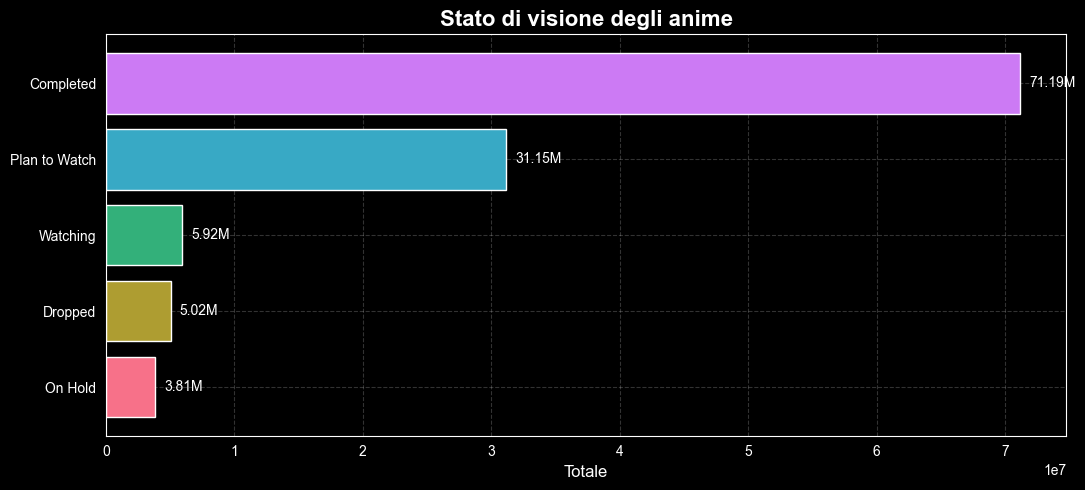

In [29]:
profiles = df_profiles.copy()

cols = utils.WATCH_STATUS_COLS
profiles[cols] = profiles[cols].fillna(0)

status_totals = profiles[cols].sum().rename_axis("status").reset_index(name="total")
status_totals["status"] = status_totals["status"].replace(utils.WATCH_STATUS_LABELS)
status_totals = status_totals.sort_values("total")

colors = sns.color_palette("husl", len(status_totals))

plt.figure(figsize=(11, 5))
bars = plt.barh(status_totals["status"], status_totals["total"], color=colors)
for bar, val in zip(bars, status_totals["total"]):
    plt.text(
        bar.get_width() + status_totals["total"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{val / 1_000_000:.2f}M", va="center", fontsize=10
    )
plt.title("Stato di visione degli anime", fontsize=16, fontweight="bold")
plt.xlabel("Totale", fontsize=12)
plt.grid(True, alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

Il grafico mostra come gli utenti organizzano la propria esperienza di visione degli anime. La categoria **Completed** domina nettamente: questo suggerisce che la piattaforma viene usata soprattutto per registrare gli anime già terminati e mantenere memoria del proprio percorso di visione.

Subito dopo compare **Plan to Watch**, una categoria molto importante perché racconta un comportamento diverso: gli utenti non usano le liste solo per guardare al passato, ma anche per costruire una sorta di **agenda personale degli anime da vedere in futuro**. In questo senso, la community non si limita a consumare contenuti, ma li organizza, li pianifica e li conserva nel tempo.

Le categorie **Watching**, **Dropped** e **On Hold** hanno valori più bassi, ma sono comunque significative. Mostrano che il rapporto con gli anime non è sempre lineare: alcuni titoli vengono seguiti mentre sono in corso, altri vengono messi in pausa, altri ancora vengono abbandonati. Questo rende visibile un aspetto importante della fruizione: davanti a un catalogo molto ampio, gli utenti selezionano continuamente cosa completare, cosa rimandare e cosa lasciare indietro.

Nel complesso, il grafico racconta una community molto attiva nella gestione della propria esperienza: gli anime non sono solo guardati, ma anche **archiviati**, **pianificati**, **monitorati** e talvolta **abbandonati**.

### Come cambia lo stato nel tempo?

In [30]:
# preparazione dati
profiles = df_profiles.copy()
profiles["joined_year"] = pd.to_datetime(
    profiles["joined"], errors="coerce"
).dt.year

cols = utils.WATCH_STATUS_COLS

profiles = profiles.dropna(subset=["joined_year"]).copy()
profiles["joined_year"] = profiles["joined_year"].astype(int)
profiles = profiles[profiles["joined_year"].between(2005, 2024)]
profiles[cols] = profiles[cols].fillna(0)

cohort = profiles.groupby("joined_year")[cols].sum()
cohort = cohort.div(cohort.sum(axis=1), axis=0) * 100
cohort_long = (
    cohort
    .reset_index()
    .melt(id_vars="joined_year", var_name="status", value_name="share")
)
cohort_long["status"] = cohort_long["status"].replace(utils.WATCH_STATUS_LABELS)
# grafico
fig = px.line(
    cohort_long,
    x="joined_year",
    y="share",
    color="status",
    markers=True,
    title="Come cambia nel tempo lo stato di visione degli anime",
    labels={
        "joined_year": "Anno di iscrizione",
        "share": "Quota sul totale (%)",
        "status": "Stato di visione"
    },
    color_discrete_sequence=sns.color_palette("husl", len(cols)).as_hex()
)

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=500,
    yaxis_ticksuffix="%"
)

fig.show()

Questo grafico mostra come cambia nel tempo la composizione degli **stati di visione** tra gli utenti registrati in anni diversi. Non osserviamo quindi solo quanti anime vengono guardati, ma soprattutto **come gli utenti gestiscono il proprio rapporto con il catalogo**: cosa completano, cosa pianificano, cosa stanno guardando, cosa mettono in pausa e cosa decidono di abbandonare.

La categoria **Completed** rimane sempre nettamente dominante, segno che la piattaforma viene usata soprattutto come archivio personale degli anime già conclusi. Subito dopo troviamo **Plan to Watch**, che mantiene un peso molto alto nel tempo: questo suggerisce che gli utenti non usano le liste solo per registrare il passato, ma anche per costruire una vera e propria lista di visione futura.

Le categorie **Dropped**, **On Hold** e **Watching** restano più basse, ma sono comunque importanti perché mostrano una fruizione non lineare. Davanti a un catalogo molto ampio, gli utenti non completano tutto: alcuni titoli vengono lasciati in sospeso, altri abbandonati, altri ancora seguiti nel tempo.

Nel complesso, il grafico racconta una community attiva e organizzata: gli anime non vengono semplicemente guardati, ma vengono **archiviati**, **pianificati**, **monitorati** e selezionati nel tempo.

**Nota sui dati:** sono stati considerati gli utenti con anno di iscrizione compreso tra **2005 e 2024**. Gli utenti fuori intervallo o con data non leggibile sono stati esclusi. I valori mancanti negli stati di visione sono stati trattati come **0** e le percentuali sono calcolate sul totale degli stati registrati per ciascun anno.

### Completamento e abbandono: cosa rivelano le statistiche per anime

Oltre alle preferenze globali della community, il dataset fornisce statistiche dettagliate per ciascun anime: quanti utenti li hanno completati, quanti li hanno abbandonati. Questi dati raccontano il rapporto reale tra gli utenti e i singoli titoli, andando oltre la semplice popolarità.

In [31]:
stats = df_stats.copy()

# considero solo anime con abbastanza utenti
stats = stats[stats["total"] >= 200].copy()

# join con anno di uscita
merged = stats.merge(
    df_details[["mal_id", "year"]].dropna(subset=["year"]),
    on="mal_id",
    how="inner"
)

merged["year"] = merged["year"].astype(int)
merged = merged[merged["year"].between(1990, 2024)]

by_year = (
    merged.groupby("year")
    .agg(
        completed=("completed", "sum"),
        dropped=("dropped", "sum"),
        total=("total", "sum"),
        n_anime=("mal_id", "nunique")
    )
    .reset_index()
)

by_year["completion_rate"] = by_year["completed"] / by_year["total"] * 100
by_year["drop_rate"] = by_year["dropped"] / by_year["total"] * 100

plot_data = by_year.melt(
    id_vars=["year", "n_anime"],
    value_vars=["completion_rate", "drop_rate"],
    var_name="metric",
    value_name="value"
)

plot_data["metric"] = plot_data["metric"].replace({
    "completion_rate": "Completamento",
    "drop_rate": "Abbandono"
})

# grafico
fig = px.line(
    plot_data,
    x="year",
    y="value",
    color="metric",
    markers=True,
    hover_data={"n_anime": True},
    title="Completamento e abbandono degli anime nel tempo",
    labels={
        "year": "Anno",
        "value": "Percentuale di utenti",
        "metric": "",
        "n_anime": "Anime considerati"
    }
)

fig.update_traces(
    line_width=2.5,
    marker_size=5
)

fig.update_layout(
    template="plotly_white",
    width=1200,
    height=500,
    yaxis_ticksuffix="%"
)

fig.show()

Il grafico mostra l’evoluzione dei tassi di **completamento** e **abbandono** degli anime nel tempo, considerando l’anno di uscita dei titoli. A differenza di una classifica dei singoli anime più completati o più abbandonati, questa visualizzazione osserva il comportamento complessivo degli utenti su larga scala.

La linea del **completamento** rimane nettamente superiore a quella dell’**abbandono** in tutto il periodo analizzato. Questo suggerisce che, nel complesso, gli anime tendono molto più spesso a essere portati a termine che interrotti. L’abbandono resta invece su valori contenuti, indicando che lasciare un anime incompleto è un comportamento presente, ma minoritario rispetto al completamento.

Le oscillazioni della linea blu mostrano che il tasso di completamento non è identico in tutti gli anni: alcuni periodi presentano valori più alti, altri cali più evidenti. Questo può dipendere dalla composizione degli anime usciti in quegli anni, dalla durata delle serie, dalla popolarità dei titoli o dal tempo che gli utenti hanno avuto per completarli.

Rispetto al grafico precedente sugli stati di visione, qui il focus cambia: non osserviamo più come gli utenti organizzano le proprie liste personali, ma quanto gli anime usciti nei diversi anni vengono effettivamente **completati** o **abbandonati**.

**Nota sui dati:** sono stati considerati solo gli anime con almeno **200 utenti totali**, per evitare percentuali basate su titoli poco rappresentativi. Gli anime sono stati collegati al loro **anno di uscita** e sono stati mantenuti solo gli anni tra **1990 e 2024**. I tassi sono calcolati in forma **aggregata per anno**: per ogni anno, il totale degli utenti che hanno completato o abbandonato gli anime viene diviso per il totale degli utenti registrati nelle statistiche degli anime di quell’anno.

## 10. IL PUBBLICO A CUI SI RIVOLGONO GLI ANIME

Gli anime non sono tutti uguali: ogni titolo è pensato per un pubblico specifico. Le categorie demografiche indicano a chi è rivolto:

- **Shounen** — ragazzi adolescenti
- **Shoujo** — ragazze adolescenti
- **Seinen** — uomini giovani/adulti
- **Josei** — donne giovani/adulte
- **Kids** — bambini

La heatmap mostra quanti anime per genere sono stati prodotti per ogni demografico.


### Distribuzione dei target demografici

In [32]:
details = df_details.copy()

details["demographics"] = details["demographics"].apply(ast.literal_eval)
details["genres"] = details["genres"].apply(utils.parse_genres)

# esclude tipi non-anime (Music, CM, PV, ecc.)
valid_types = ["TV", "Movie", "OVA", "ONA", "Special", "TV Special"]
details = details[details["type"].isin(valid_types)]

# una riga per ogni coppia demografico–genere
details = details.explode("demographics").explode("genres")
details = details.dropna(subset=["demographics", "genres"])

# conta le combinazioni demografico × genere
heat = (details.groupby(["demographics", "genres"]).size().reset_index(name="count"))

# esclude generi con meno di 20 anime per evitare "rumore"
min_count = heat.groupby("genres")["count"].sum()
valid_genres = min_count[min_count >= 20].index
heat = heat[heat["genres"].isin(valid_genres)]

# pivot
heat_pivot = heat.pivot(index="demographics", columns="genres", values="count").fillna(0)

fig = px.imshow(
    heat_pivot,
    color_continuous_scale="YlOrRd",
    aspect="auto",
    text_auto=True,
    labels={"color": "N° anime", "x": "Genere", "y": "Demografica"},
    title="Quale genere domina in ogni target demografico?"
)
fig.update_layout(height=500, width=1200)
fig.show()


La heatmap rivela come ogni demografico abbia il suo territorio di genere ben definito.

I **Kids** dominano il **Fantasy** con 1.786 anime, il numero più alto dell'intera mappa. Non è un caso: il Fantasy è il linguaggio dei bambini, quel mondo di magia e creature che cattura l'immaginazione fin dai primi anni. Franchise come *Pokémon*, *Doraemon* e *Digimon* ciascuno con decine di stagioni, film e special contati separatamente, ne spiegano il primato. La Comedy segue con 1.267, confermando che intrattenimento leggero e mondi fantastici sono i pilastri del contenuto per i più piccoli.

Lo **Shounen** costruisce il suo impero sull'Action (898) e sulla Comedy (978), con il Fantasy a completare il trittico (521). È la ricetta classica dell'anime per adolescenti: avventura, risate e poteri straordinari. Un formato che ha funzionato per decenni e continua a funzionare.

Il **Seinen** si distingue per la sua diversità. È l'unico demografico con una presenza significativa in **Ecchi** (140) e **Horror** (70), generi praticamente assenti altrove. Il pubblico adulto cerca contenuti che i filtri demografici più giovani non permettono, e l'industria risponde esattamente in quel modo.

Lo **Shoujo** trova la sua identità nel **Romance** (250) e nel **Drama** (170). Sono i generi dell'emozione e delle relazioni, e la distanza dai numeri dell'Action shounen racconta quanto le due demografiche abitino universi narrativi completamente separati.

Il **Josei** è la categoria più piccola in assoluto: i numeri bassi su ogni genere riflettono una produzione storicamente limitata. Eppure il suo picco nel **Romance** (59) e nel **Drama** (41) ne traccia chiaramente l'identità: storie adulte al femminile, più mature e realistiche rispetto allo Shoujo.

>**Nota:** Nella heatmap, risultano 11 anime di genere _horror_ e 15 _romance_ con il target **kids**. Il dato potrebbe essere sbagliato nel dataset analizzato.



### Come evolgono nel tempo?

In [33]:
details = df_details.copy()
# filtro e preparazione
details = details[details['year'] < 2025].copy()
details['demographics'] = details['demographics'].apply(eval)
details = details.explode('demographics')
# conteggio per anno e demografico
counts = (details.groupby(['year', 'demographics']).size().reset_index(name='anime_count'))
# creazione grafico con Plotly
fig = px.line(counts, x='year', y='anime_count', color='demographics', markers=True,
    title="Evoluzione dei target demografici nel tempo",
    labels={'year': 'Anno', 'anime_count': 'Numero di titoli', 'demographics': 'Target Demografico'},
    hover_data={'year': True, 'anime_count': True, 'demographics': True})
fig.update_traces(marker=dict(size=5), line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Cinque linee, una sola storia
Per decenni, tutte e cinque le categorie demografiche avanzano appiattite sul fondo del grafico, un groviglio sottile, quasi invisibile. L'industria esiste, ma non ha ancora trovato la velocità.
Il primo a staccarsi è il blu, i Kids. Dagli anni Settanta in poi la loro linea sale con costanza, stagione dopo stagione, anno dopo anno, mentre Shounen, Seinen, Shoujo e Josei restano ben al di sotto, quasi immobili a confronto.
Poi arriva il momento più drammatico del grafico: la linea blu tocca il suo massimo assoluto, un picco che nessun'altra categoria ha mai sfiorato.
E poi crolla. In un solo anno si dimezza, con una caduta verticale che nessun'altra linea mostra.
Ma mentre i Kids precipitano, Shounen e Seinen continuano a salire, le uniche due che nell'ultima parte del grafico puntano ancora verso l'alto. Come se il testimone fosse passato di mano: l'industria stava smettendo di parlare ai bambini, e stava cominciando a parlare agli adulti.

---

## 11. CONCLUSIONE - GLI ANIME COME ECOSISTEMA CULTURALE E GLOBALE

Dalla crescita della produzione ai target demografici, il percorso mostra che gli anime funzionano come un ecosistema: opere, generi, utenti, personaggi, voci e professionisti si intrecciano nel tempo, costruendo un fenomeno culturale sempre più ampio.

**Produzione e qualità**

La produzione di anime è cresciuta in modo lento e costante per gran parte del Novecento, per poi esplodere dopo il 2000 e raggiungere il picco storico intorno al 2017.
La qualità percepita dagli utenti ha seguito una traiettoria diversa: bassa nelle prime decadi, in crescita dagli anni '60, stabile su valori alti dagli anni '90 in poi.
L'industria si è espansa senza abbassare gli standard percepiti dalla community.

**Origini e formati**

Contrariamente a quanto si potrebbe pensare, la fonte più comune degli anime non è il manga ma le **opere originali**: l'industria anime mantiene una forte capacità creativa autonoma. Gli adattamenti manga sono comunque la seconda fonte più rappresentata, confermandone il ruolo centrale come serbatoio narrativo. Il formato televisivo ha sempre dominato; gli OVA sono cresciuti negli anni '80 come spazio di sperimentazione, ma la TV è rimasta il vettore principale.

**Generi e preferenze non sempre coincidono**

Comedy, Action e Fantasy dominano la produzione, ma le preferenze degli utenti risultano più distribuite. Generi come Drama e Romance sono apprezzati più di quanto vengano prodotti, mentre Comedy e Fantasy mostrano una sovraofferta rispetto alla domanda reale dei fan. L'industria segue logiche proprie, non sempre allineate al gusto del pubblico.

**I personaggi: pochi protagonisti, molto amati**

L'84% dei personaggi degli anime sono figure secondarie; solo il 16% sono protagonisti. Eppure, il 70% dei protagonisti riceve almeno un preferito dagli utenti, contro il 32.6% dei personaggi secondari. In minoranza numerica, i protagonisti riescono quasi sempre a
lasciare il segno nella memoria del pubblico.

**I doppiatori: pochi professionisti, molto lavoro**

Anche il doppiaggio segue una distribuzione sbilanciata: il 69.8% dei doppiatori ha interpretato al massimo 10 personaggi, mentre solo il 3% supera i 100 ruoli. Un piccolo gruppo di professionisti concentra la maggior parte dell'esperienza accumulata nel settore.Il doppiaggio è inoltre un fenomeno globale: dopo il giapponese e l'inglese, francese e spagnolo si posizionano tra le lingue più usate, riflettendo la diffusione mondiale del medium.

**Gli studi: volume contro qualità**

Non tutti gli studi percorrono la stessa strada. Alcuni costruiscono cataloghi enormi da centinaia di titoli, altri producono poco ma con punteggi medi molto alti. I dati mostrano chiaramente che volume e qualità non sono correlati: gli studi con i punteggi più alti non sono necessariamente quelli che producono di più. Gli anime più popolari tendono inoltre ad avere produzioni più complesse, con più persone coinvolte e più ruoli diversi nei credits.

**Una community globale**

Gli utenti sono presenti in tutto il mondo, con una forte concentrazione in Giappone e Stati Uniti. Chi crea gli anime è invece ancora prevalentemente giapponese, affiancato da collaboratori americani: un prodotto fortemente locale che ha raggiunto un pubblico globale. La community online è cresciuta costantemente dopo il 2000, con un picco eccezionale nel 2020-2021 durante i lockdown pandemici.

**Gli utenti gestiscono attivamente la loro esperienza**

La categoria di visione più comune è "Completed": la piattaforma viene usata principalmente come archivio personale degli anime già conclusi. "Plan to Watch" è la seconda categoria più grande, mostrando che gli utenti costruiscono anche un'agenda personale futura. Il tasso di completamento supera nettamente quello di abbandono in tutti gli anni analizzati: non basta attirare attenzione, bisogna riuscire a mantenere l'interesse fino alla fine.

**Un mezzo, non un genere**

Il dato forse più significativo dell'intero percorso è la varietà demografica: Shounen, Shoujo, Seinen, Josei, Kids. Gli anime non si rivolgono a un pubblico unico. I Kids hanno dominato per decenni attraverso il Fantasy, mentre lo Shounen è esploso dagli anni 2000 diventando la categoria più produttiva in assoluto. Questa capacità di adattarsi a pubblici, età e gusti radicalmente diversi è probabilmente il motivo principale per cui il fenomeno continua a crescere a livello globale.
